### 1. Organizacja i cel

Zbuduj model przewidujący cenę transakcji nieruchomości na podstawie jej opisu i informacji o wskazanym dniu transakcji. Następnie zbadaj, jak decyzje dotyczące danych, cech i regularyzacji wpływają na jakość predykcji. Osobna, krótka część dotyczy klasyfikacji SVM. Scenariusz oceny: przyszłe transakcje nieruchomości niewidzianych wcześniej przez model.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

NR_INDEKSU = 33322 
WARIANT = NR_INDEKSU % 4
df = pd.read_csv('domy.csv')

### 2. Dane

Dane są zapisane w domy.csv. Każdy wiersz opisuje transakcję. price jest ceną w jednostkach pieniężnych zbioru (dolarach), powierzchnie sqft_* są podane w stopach kwadratowych. id identyfikuje nieruchomość; zipcode jest kategorią, a nie wielkością liczbową. date zawiera datę transakcji. Znaczenie nazw: sqft_living — powierzchnia mieszkalna, sqft_lot — działka, sqft_above — część nadziemna, sqft_basement — piwnica, yr_built — rok budowy, yr_renovated — rok renowacji. Zero w yr_renovated traktuj jako brak odnotowanej renowacji. grade, condition i view są ocenami porządkowymi. Zmienne z końcówką 15 traktuj jako dostarczone cechy otoczenia; nie obliczaj ich ponownie z cen ani nie zakładaj ich aktualności, której nie potwierdzają dane.

Przyjmujemy, że cechy opisowe są dostępne w chwili wyceny. W rzeczywistym wdrożeniu należałoby potwierdzić moment ich pozyskania. Nie pobieraj z internetu gotowych cen dla tych samych nieruchomości.

Zastosuj następujący podział przed analizą rozkładów, korelacji i doborem przekształceń:

| Część | Daty transakcji | Przeznaczenie |
|---|---|---|
| Trening | wcześniej niż 2015-01-01 | przygotowanie danych i uczenie |
| Walidacja | od 2015-01-01 do 2015-02-28 włącznie | wybór parametrów i eksperymenty |
| Test | od 2015-03-01 | jedna końcowa ocena |

Najpierw usuń z treningu i walidacji wszystkie wiersze, których id występuje w teście. Następnie usuń z treningu wiersze, których id występuje w pozostałej walidacji. Nie usuwaj powtórzeń wewnątrz pojedynczej części tylko dlatego, że id jest takie samo: mogą to być różne transakcje. Liczebności kontrolne dla dostarczonego pliku po rozdzieleniu id: trening 14 497, walidacja 2220, test 4752. Zbiory identyfikatorów między częściami muszą być rozłączne. Udostępniony szkielet zawiera ten podział; wyjaśnij jego sens.

Poza kontrolą schematu, dat i identyfikatorów test pozostaje niewykorzystywany aż do końca. Analizę eksploracyjną wykonuj na treningu. Wszystkie parametry skalowania, uzupełniania braków, kodowania kategorii, selekcji cech i progów obliczaj z treningu. Użycie walidacji do wyboru hiperparametrów jest dozwolone. Nie wolno dopasowywać skalera osobno do walidacji lub testu.

Nie używaj price ani cech zawierających rzeczywistą cenę przewidywanej transakcji jako wejścia do modelu. Nie wykorzystuj id jako predyktora. Datę możesz wykorzystać do deterministycznych cech kalendarzowych lub wieku budynku, jeżeli uzasadnisz ich dostępność. Nie stosuj kodowania kategorii średnią ceną w tym projekcie. Wszystkie modele w porównaniu mają być oceniane na tych samych wierszach walidacji/testu. Nie odrzucaj stamtąd przykładów z powodu dużego błędu lub nietypowej ceny.

In [2]:
df['sale_date'] = pd.to_datetime(df['date'], format='%Y%m%dT%H%M%S')
test = df.loc[df.sale_date >= '2015-03-01'].copy()
val = df.loc[(df.sale_date >= '2015-01-01') & (df.sale_date < '2015-03-01')].copy()
train = df.loc[df.sale_date < '2015-01-01'].copy()
train = train.loc[~train.id.isin(test.id)].copy()
val = val.loc[~val.id.isin(test.id)].copy()
train = train.loc[~train.id.isin(val.id)].copy()
assert (len(train), len(val), len(test)) == (14497, 2220, 4752)
assert not (set(train.id) & set(val.id))
assert not (set(train.id) & set(test.id))
assert not (set(val.id) & set(test.id))
print('Trening / walidacja / test:', len(train), len(val), len(test))
# Od tego miejsca do sekcji końcowej nie wykorzystuj testu w analizie.

# podział zbioru wynika z faktu, że model ma uczyć się na najstarszych danych, aby móc przewidywać ceny na danych z późniejszego okresu.
# Ponadto, rozłączność id gwarantuje brak przecieku danych (priorytet id ma zbiór testowy, a następnie walidacyjny)

Trening / walidacja / test: 14497 2220 4752


### 3. Zadanie 1 — audyt danych i protokół

Znajdź co najmniej cztery własności lub problemy treningu istotne dla modelowania. Uwzględnij co najmniej jeden problem spójności danych, jedną zależność między cechami i jedną własność rozkładu ceny. Każdy wpis ma zawierać dowód liczbowy, możliwą konsekwencję i decyzję. Odróżniaj podejrzaną obserwację od potwierdzonego błędu. Nie zmieniaj wartości na podstawie domysłu bez pokazania uzasadnienia.

Opisz sposób reprezentacji zipcode i pozostałych cech, postępowanie z brakami i wartościami podejrzanymi. Przekształcenia muszą obsługiwać nieznaną kategorię oraz brak wartości w nowym obiekcie. Reguły ustalone na treningu stosuj bez zmian do walidacji i testu. Nie jest wymagane znalezienie wszystkich problemów ani odrzucenie wszystkich odstających punktów.

Przed właściwymi eksperymentami zapisz trzy sprawdzalne hipotezy, np. o wpływie regularyzacji, transformacji celu lub grupy cech. Wskaż główną miarę wyboru modelu regresyjnego: w tym projekcie jest nią MAE walidacyjne. RMSE i R² są miarami uzupełniającymi. Nie zmieniaj kryterium po zobaczeniu testu.

,count,mean,min,25%,50%,75%,max,std
price,"14,497.00","540,978.83","78,000.00","323,000.00","450,000.00","648,000.00","7,700,000.00","369,382.32"
bedrooms,"14,497.00",3.38,0.00,3.00,3.00,4.00,33.00,0.94
bathrooms,"14,497.00",2.13,0.00,1.75,2.25,2.50,8.00,0.77
sqft_living,"14,497.00","2,101.80",290.00,"1,440.00","1,940.00","2,580.00","13,540.00",930.62
sqft_lot,"14,497.00","14,972.60",520.00,"5,031.00","7,632.00","10,800.00","1,074,218.00","37,613.95"
floors,"14,497.00",1.50,1.00,1.00,1.50,2.00,3.50,0.54
waterfront,"14,497.00",0.01,0.00,0.00,0.00,0.00,1.00,0.09
view,"14,497.00",0.23,0.00,0.00,0.00,0.00,4.00,0.77
condition,"14,497.00",3.43,1.00,3.00,3.00,4.00,5.00,0.66
grade,"14,497.00",7.69,1.00,7.00,7.00,8.00,13.00,1.18


Wymiary:  (14497, 22)
Łączna liczba braków: 0
Zduplikowane wiersze: 0
Unikalne nieruchomości: 14464


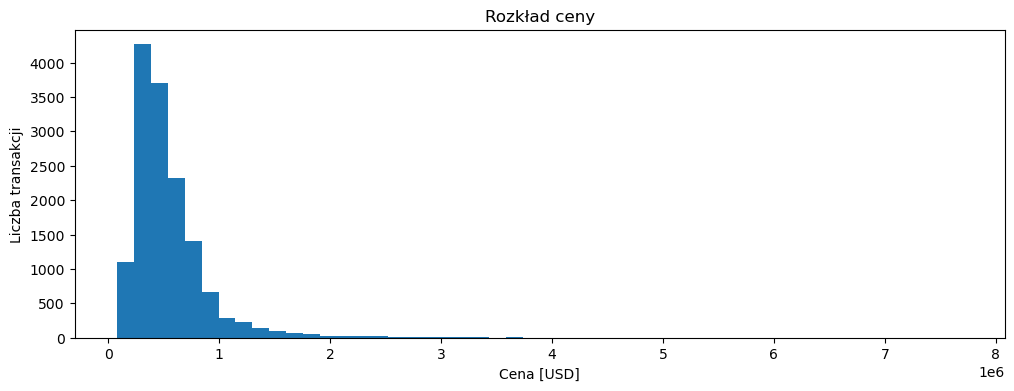

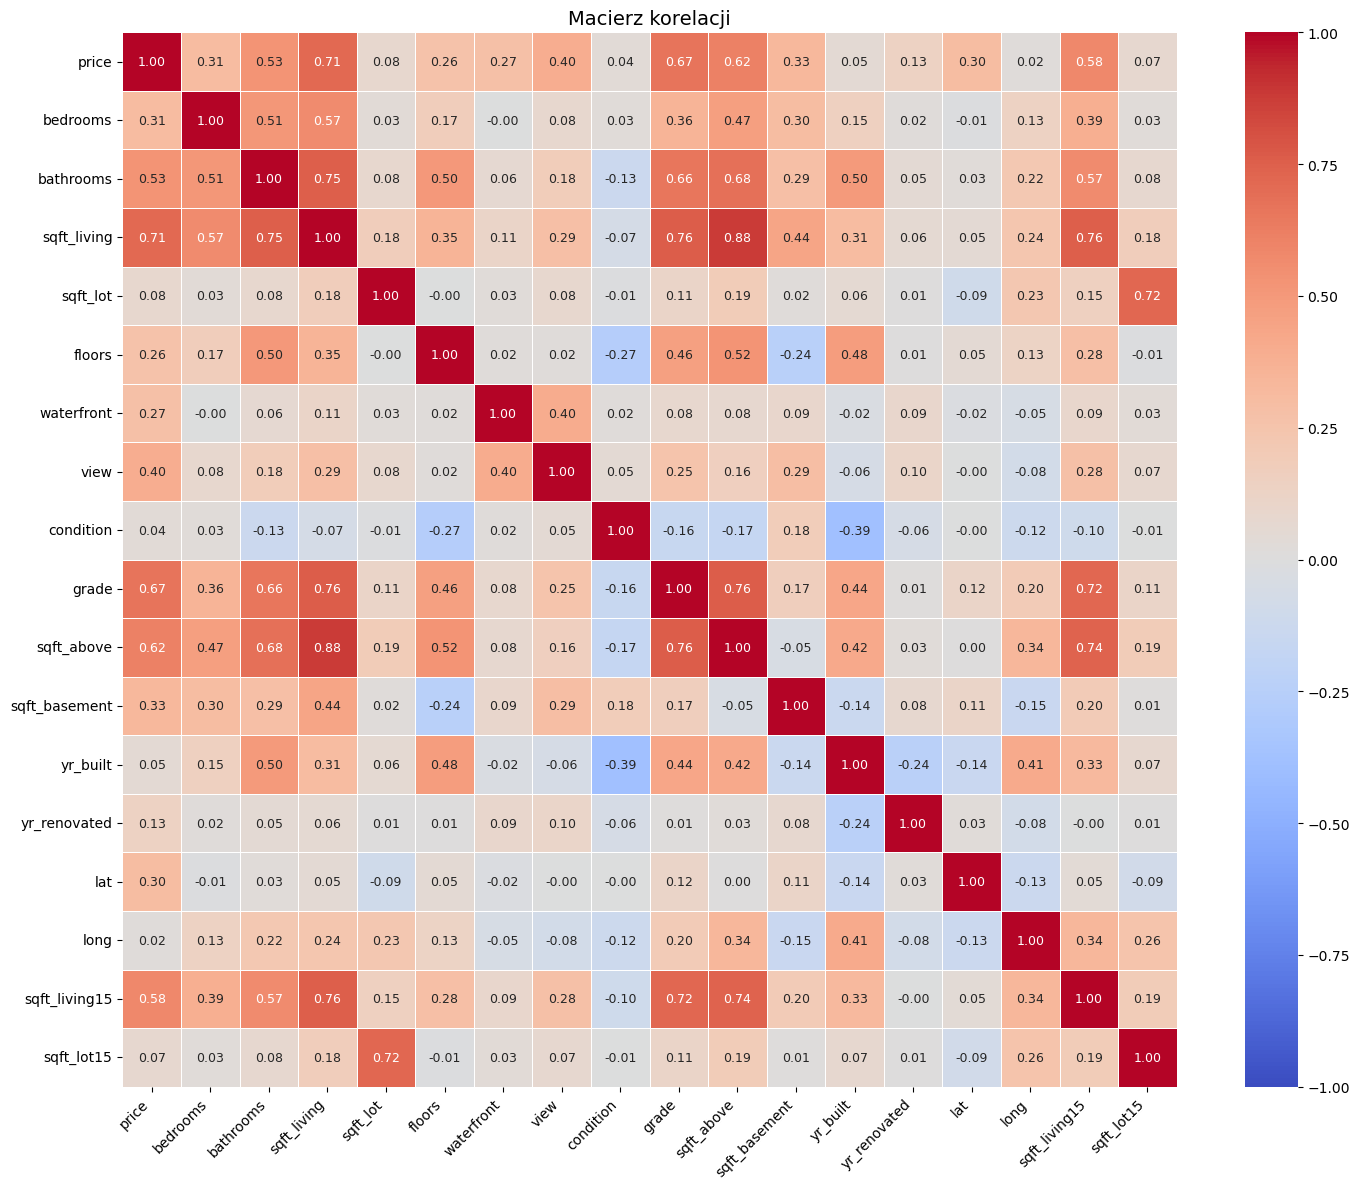


niespójności: 0
0 sypialni: 9
0 łazienek: 6
Maksymalna liczba sypialni: 33
Rok budowy późniejszy od roku transakcji: 12
Rok renowacji późniejszy od roku transakcji: 6
Brak renowacji: 13833
Liczba kategorii zipcode: 70

 Przykładowe podejrzane rekordy:


,bedrooms,bathrooms,sqft_living,yr_built,sale_date,price
875,0,0.00,3064,1990,2014-06-12,"1,095,000.00"
1763,4,4.00,3570,2015,2014-06-25,"597,326.00"
2687,1,1.00,710,2015,2014-10-29,"385,195.00"
6994,0,0.00,4810,1990,2014-06-24,"1,295,650.00"
7526,5,2.75,2730,2015,2014-12-31,"614,285.00"
8039,2,1.50,1200,2015,2014-06-24,"455,000.00"
9854,0,0.00,1470,1996,2014-12-23,"235,000.00"
14489,2,2.25,1570,2015,2014-08-26,"500,000.00"
15870,33,1.75,1620,1947,2014-06-25,"640,000.00"
17098,3,2.00,1380,2015,2014-06-17,"350,000.00"


In [3]:
pd.set_option("display.float_format", "{:,.2f}".format)
display(train.describe().T) #transpozycja dla lepszej czytelnosci
print("Wymiary: ", train.shape)
print("Łączna liczba braków:", train.isna().sum().sum())
print("Zduplikowane wiersze:", train.duplicated().sum())
print("Unikalne nieruchomości:", train["id"].nunique())

plt.figure(figsize=(12, 4))
plt.hist(train["price"], bins=50)
plt.xlabel("Cena [USD]")
plt.ylabel("Liczba transakcji")
plt.title("Rozkład ceny")
plt.show()

korelacje = train.select_dtypes(include="number").drop(columns=["id", "zipcode"], errors="ignore").corr()
plt.figure(figsize=(15, 12))
sns.heatmap(
    korelacje,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot_kws={"size": 9},
    linewidths=0.5,
    square=True
)
plt.title("Macierz korelacji", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

niespojne = train[train["sqft_living"] != train["sqft_above"] + train["sqft_basement"]]
print("\nniespójności:", len(niespojne))

# dziwne przypadki
print("0 sypialni:", (train["bedrooms"] == 0).sum())
print("0 łazienek:", (train["bathrooms"] == 0).sum())
print("Maksymalna liczba sypialni:", train["bedrooms"].max())

print("Rok budowy późniejszy od roku transakcji:", (train["yr_built"] > train["sale_date"].dt.year).sum())
print("Rok renowacji późniejszy od roku transakcji:", (train["yr_renovated"] > train["sale_date"].dt.year).sum())
print("Brak renowacji:", (train["yr_renovated"] == 0).sum())
print("Liczba kategorii zipcode:", train["zipcode"].nunique())

#przegląd podejrzanych rekordów
print("\n Przykładowe podejrzane rekordy:")
display(
    train.loc[
        (train["bedrooms"] > 20) |
        ((train["bedrooms"] == 0) & (train["bathrooms"] == 0))|
        (train["yr_built"] > train["sale_date"].dt.year),
        ["bedrooms", "bathrooms", "sqft_living", "yr_built", "sale_date", "price"]
    ].head(10)
)

| Obserwacja | Dowód liczbowy | Możliwa konsekwencja | Decyzja |
| :--- | :--- | :--- | :--- |
| 1. Prawostronna asymetria ceny | Średnia 540 979 USD; mediana 450 000 USD; maksimum 7,7 mln USD | Drogie nieruchomości mogą silnie wpływać na dopasowanie regresji | Zachowanie danych i sprawdzenie transformacji logarytmicznej ceny |
| 2. Silne korelacje między cechami | sqft_living i sqft_above: 0,88; sqft_living i grade: 0,76 | Współzależność cech może utrudniać interpretację współczynników | Zachowanie cech i zbadanie wpływu regularyzacji |
| 3. Podejrzane liczby pomieszczeń | 9 nieruchomości z 0 sypialni, 6 z 0 łazienek; maksimum 33 sypialnie przy 1620 sqft | Nietypowe wartości mogą wpływać na dopasowanie modelu | Zostawienie rekordów bez potwierdzenia błędu |
| 4. Niespójności czasowe | 12 przypadków budowy i 6 renowacji po dacie transakcji | Możliwe błędy danych lub wykorzystanie informacji z przyszłości | Zostawienie rekordów, zamaskowanie i imputacja medianą treningową |
| 5. Powtarzające się nieruchomości | 14 497 transakcji i 14 464 unikalne id | Jedna nieruchomość może występować w kilku transakcjach | Kontrola rozłączności id między zbiorami |

**Miejsce na wyprowadzenie, wyniki i interpretację:**

- Cechy: price jest zmienną docelową. id służy do identyfikacji nieruchomości, a date i sale_date do podziału chronologicznego, więc nie będą bezpośrednimi predyktorami.
- Kod pocztowy: zipcode traktuję jako zmienną kategoryczną (kodowanie one-hot). Nieznane kategorie nie będą powodować błędu predykcji.
- Pozostałe cechy: cechy liczbowe zostaną odpowiednio skalowane. grade, condition i view zachowają reprezentację porządkową.
- Braki danych: w treningu nie stwierdzono braków. Dla nowych obserwacji przewiduję uzupełnianie braków liczbowych medianą z treningu oraz osobną obsługę brakujących kategorii.
- Wartości podejrzane: nie zostaną usunięte ani poprawione bez potwierdzenia błędu. Zero w yr_renovated oznacza brak renowacji.
- Zasada walidacji: wszystkie parametry przekształceń będą wyznaczane wyłącznie na treningu i stosowane bez ponownego dopasowania do walidacji oraz testu.

Główną miarą oceny modeli regresyjnych będzie MAE na zbiorze walidacyjnym. RMSE i R² będą miarami uzupełniającymi. Zbiór testowy zostanie wykorzystany dopiero do końcowej oceny wybranego modelu.

**Hipotezy H1–H3 (zapisz przed eksperymentami):**

1. Wpływ regularyzacji: Zastosowanie regularyzacji Ridge zmniejszy MAE walidacyjne w porównaniu ze zwykłą regresją liniową, ze względu na występujące korelacje między cechami.
2. Transformacja zmiennej docelowej: Zastosowanie transformacji logarytmicznej ceny zmniejszy MAE walidacyjne w porównaniu z modelem uczonym na oryginalnej skali ceny, ze względu na prawostronną asymetrię jej rozkładu.
3. Wpływ dodatkowych cech: Dodanie trzech nowych cech opisujących nieruchomość zmniejszy MAE walidacyjne względem bazowego modelu Ridge.

### 4. Zadanie 2 — własny Ridge i jego weryfikacja

Dla macierzy przygotowanych cech X o n wierszach i p kolumnach zaimplementuj:

$$J(w,b)=\frac{1}{2n}\|Xw+b\mathbf{1}-y\|_2^2+\frac{\lambda}{2}\|w\|_2^2.$$

Wyprowadź gradient po w i b, a następnie zaimplementuj uczenie metodą pełnego gradientu oraz predict. Wyraz wolny nie jest regularyzowany. Wymagane argumenty: lambda, długość kroku, maksymalna liczba iteracji oraz tolerancja zakończenia. Zwracaj informację o liczbie iteracji, przyczynie zakończenia i historii funkcji celu. Duplikowanie stałej kolumny i osobnego wyrazu wolnego jest zbędne.

Można algebraicznie przyspieszyć pełny gradient przez wcześniejsze obliczenie XᵀX i Xᵀy. Wyjaśnij, dlaczego daje to tę samą aktualizację. Skalowanie celu wyłącznie na treningu jest dopuszczalne, ale trzeba opisać jego wpływ na zapis funkcji celu i odwrócić transformację predykcji. Oceniaj wszystkie modele w tej samej skali ceny.

Wykonaj trzy sprawdzenia na małym, deterministycznym przykładzie syntetycznym:

1. Sprawdź gradient różnicami centralnymi dla wszystkich współczynników i wyrazu wolnego (np. 30 obserwacji, 4 cechy, epsilon=10⁻⁶). Względny błąd normy gradientu: nie większy niż 10⁻⁵, z mianownikiem max(1, norma gradientu analitycznego, norma gradientu numerycznego).
2. Dla lambda=0.1 porównaj predykcje z rozwiązaniem równań normalnych dla tej samej funkcji celu i niekaranego b. Względny błąd predykcji ma być mniejszy niż 10⁻³: norma różnicy podzielona przez max(1, norma predykcji referencyjnej). Użyj solve, nie jawnego odwracania macierzy.
3. Dla tego samego punktu startowego pokaż przebieg J dla trzech kroków: bardzo małego, zapewniającego zbieżność i zbyt dużego. Dobierz je tak, aby różnica była widoczna; wykryj rozbieżność zamiast kontynuować obliczenia do NaN. Wyjaśnij wyniki. Nie trzeba celowo rozbiegać modelu na pełnym zbiorze domów.

Na danych rzeczywistych sprawdzaj zbieżność każdej konfiguracji. Samo osiągnięcie limitu iteracji nie potwierdza poprawnego rozwiązania. W weryfikacji bibliotecznej pamiętaj, że różne biblioteki inaczej normalizują stratę; nie porównuj bez uzgodnienia parametrów dwóch różnych funkcji celu.

In [4]:
class RidgeGD:
    def __init__(self, lam=0.1, step=0.01, max_iter=10000, tol=1e-8):
        self.lam = lam
        self.step = step
        self.max_iter = max_iter
        self.tol = tol

    def fit(self, X, y):
        # uczenie, kryterium stopu, historia J, kontrola rozbieżności
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()

        n, p = X.shape
        self.w_ = np.zeros(p)
        self.b_ = 0.0
        self.history_ = []
        self.n_iter_ = 0
        self.stop_reason_ = "max_iter"
        self.converged_ = False

        # kontrola parametrów
        if self.lam < 0 or self.step <= 0:
            raise ValueError("lam musi być >= 0, a step > 0")

        # Początkowa wartość funkcji celu
        J = self.objective(X, y, self.w_, self.b_)
        self.history_.append(J)

        for i in range(self.max_iter):
            dw, db = self.gradient(X, y, self.w_, self.b_) #pełny gradient
            w_new = self.w_ - self.step * dw
            b_new = self.b_ - self.step * db

            J_new = self.objective(X, y, w_new, b_new)

            #wykrywanie rozbieżności
            # Wykrywanie rozbieżności
            if not np.isfinite(J_new) or J_new > 10 * self.history_[0]:
                self.stop_reason_ = "divergence"
                break

            self.w_ = w_new
            self.b_ = b_new
            self.history_.append(J_new)
            self.n_iter_ = i + 1

            # kontrola zbieżności gradientu
            dw_new, db_new = self.gradient(X, y, self.w_, self.b_)
            grad_norm = np.sqrt(np.dot(dw_new, dw_new) + db_new**2)
            
            if grad_norm <= self.tol:
                self.stop_reason_ = "gradient_tol"
                self.converged_ = True
                break
            
            # z zaałożenia mała zmiana J nie jest samodzielnym dowodem zbieżności
            if abs(J - J_new) <= self.tol * max(1.0, abs(J)):
                self.stop_reason_ = "objective_tol"
                self.converged_ = False
                break
            J = J_new

        # końcowa norma gradientu
        dw, db = self.gradient(X, y, self.w_, self.b_)
        self.grad_norm_ = np.sqrt(np.dot(dw, dw) + db**2)
        return self

    def predict(self, X):
        #predykcja dla nowych danych.
        X = np.asarray(X, dtype=float)
        return X @ self.w_ + self.b_

    # funkcja celu Ridge
    def objective(self, X, y, w, b):
        n = len(y)
        e = X @ w + b - y
        return np.dot(e, e) / (2 * n) + self.lam * np.dot(w, w) / 2

    #gradient po wagach i wyrazie wolnym
    def gradient(self, X, y, w, b):
        n = len(y)
        e = X @ w + b - y
        dw = X.T @ e / n + self.lam * w
        db = np.sum(e) / n
        return dw, db

Błąd względny gradientu: 2.0099675961188191e-10
Błąd względny predykcji: 8.448924308826711e-07
Liczba iteracji: 301
Przyczyna zatrzymania: objective_tol
Krok=0.0001: iteracje=400, zatrzymanie=max_iter
Krok=0.1: iteracje=301, zatrzymanie=objective_tol
Krok=2.0: iteracje=3, zatrzymanie=divergence


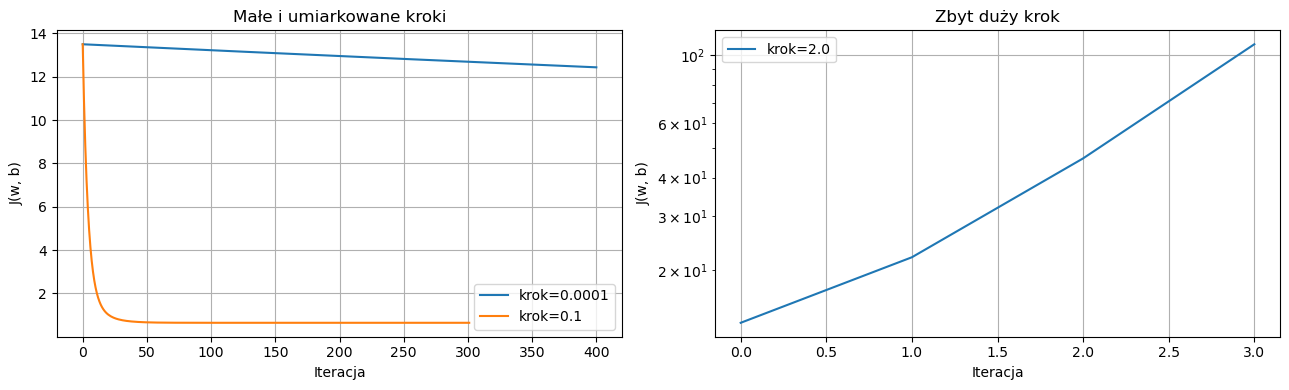


Predykcje nowych obserwacji: [10.14111451  1.92066315]


In [5]:
rng = np.random.default_rng(7)
X_check = rng.normal(size=(30, 4))
y_check = X_check @ np.array([2., -1., 0.5, 3.]) + 4 + rng.normal(scale=.1, size=30)

model = RidgeGD(lam=0.1) #sprawdzenie gradientu rożnicami centralnymi
w = np.array([0.5, -0.3, 0.8, 1.2])
b = 0.7
eps = 1e-6
dw, db = model.gradient(X_check, y_check, w, b)
grad_analityczny = np.r_[dw, db]

grad_numeryczny = np.zeros(5)

for j in range(4):
    w_plus = w.copy()
    w_minus = w.copy()
    w_plus[j] += eps
    w_minus[j] -= eps

    grad_numeryczny[j] = (
        model.objective(X_check, y_check, w_plus, b) -
        model.objective(X_check, y_check, w_minus, b)
    ) / (2 * eps)

grad_numeryczny[4] = (
    model.objective(X_check, y_check, w, b + eps) -
    model.objective(X_check, y_check, w, b - eps)
) / (2 * eps)

blad_gradientu = (
    np.linalg.norm(grad_analityczny - grad_numeryczny) /
    max(1, np.linalg.norm(grad_analityczny),
        np.linalg.norm(grad_numeryczny))
)

print("Błąd względny gradientu:", blad_gradientu)
assert blad_gradientu <= 1e-5

# porównanie z rozwiązaniem równań normalnych
lam = 0.1
n, p = X_check.shape

# kolumna jedynek reprezentuje niekarany wyraz wolny
A = np.column_stack([np.ones(n), X_check])
D = np.eye(p + 1)
D[0, 0] = 0 #brak reularyzacji wyrazu wolnego

# rozwiązanie bez odwracania macierzy - sprwdzam czy popawna implementacja RidgeGD
theta = np.linalg.solve(
    A.T @ A + n * lam * D,
    A.T @ y_check
)

pred_ref = A @ theta
model_gd = RidgeGD(lam=lam, step=0.1, max_iter=10000, tol=1e-12)
model_gd.fit(X_check, y_check)
pred_gd = model_gd.predict(X_check)

blad_predykcji = (
    np.linalg.norm(pred_gd - pred_ref) /
    max(1, np.linalg.norm(pred_ref))
)

print("Błąd względny predykcji:", blad_predykcji)
print("Liczba iteracji:", model_gd.n_iter_)
print("Przyczyna zatrzymania:", model_gd.stop_reason_)
assert blad_predykcji < 1e-3

# wpływ długości kroku na zbieżność
kroki = [1e-4, 0.1, 2.0]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

for krok in kroki:
    m = RidgeGD(lam=0.1, step=krok, max_iter=400, tol=1e-12)
    m.fit(X_check, y_check)
    print(f"Krok={krok}: iteracje={m.n_iter_}, " f"zatrzymanie={m.stop_reason_}")

    if krok < 1:
        ax[0].plot(m.history_, label=f"krok={krok}")
    else:
        ax[1].plot(m.history_, label=f"krok={krok}")

# stabilne kroki
ax[0].set_title("Małe i umiarkowane kroki")
ax[0].set_xlabel("Iteracja")
ax[0].set_ylabel("J(w, b)")
ax[0].legend()
ax[0].grid(True)

# krok prowadzący do rozbieżności
ax[1].set_title("Zbyt duży krok")
ax[1].set_xlabel("Iteracja")
ax[1].set_ylabel("J(w, b)")
ax[1].set_yscale("log")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

# predykcja dla danych spoza treningu
X_new = np.array([
    [1.0, 0.5, -1.0, 2.0],
    [0.0, 1.0, 0.5, -0.5]
])
pred_new = model_gd.predict(X_new)
print("\nPredykcje nowych obserwacji:", pred_new)
assert pred_new.shape == (2,)
assert np.all(np.isfinite(pred_new))

**Miejsce na wyprowadzenie, wyniki i interpretację:**

**Wyprowadzanie gradientu**
Funkcja celu Ridge ma postać:
$$J(w,b)=\frac{1}{2n}\|Xw+b\mathbf{1}-y\|_2^2+\frac{\lambda}{2}\|w\|_2^2$$

Oznaczając $e=Xw+b\mathbf{1}-y$, otrzymujemy gradienty:

$$\nabla_w J=\frac{1}{n}X^Te+\lambda w$$

$$\frac{\partial J}{\partial b}=\frac{1}{n}\mathbf{1}^Te$$

Wyraz wolny b nie jest regularyzowany.

Aktualizacja parametrów metodą pełnego spadku gradientowego:
$$w_{k+1}=w_k-\eta\nabla_w J$$

$$b_{k+1}=b_k-\eta\frac{\partial J}{\partial b}$$

gdzie eta $\eta\$ oznacza długość kroku.

Istnieje możliwość przyspieszenia obliczeń, ponieważ gradient po wagach można przekształcić algebraicznie:

$$\nabla_w J =\frac{1}{n}(X^TXw+bX^T\mathbf{1}-X^Ty)+\lambda w$$

Wcześniejsze obliczenie $X^TX$, $X^Ty$ i $\X^T\mathbf{1}$ pozwala uniknąć powtarzania części mnożeń macierzowych w każdej iteracji. Obie postacie gradientu są algebraicznie równoważne, dlatego dają takie same aktualizacje parametrów, z dokładnością do błędów numerycznych. Zastosowałam bezpośrednie obliczanie pełnego gradientu.

**Weryfikacja implementacji**

1. Sprawdzenie gradientu. Błąd względny gradientu analitycznego względem gradientu wyznaczonego różnicami centralnymi wyniósł:

$$2{,}01\cdot10^{-10}<10^{-5}$$

Warunek został spełniony, co potwierdza poprawność obliczania gradientów po współczynnikach i wyrazie wolnym.

2. Porównanie z równaniami normalnymi. Dla $lambda=0{,}1$ otrzymano błąd względny predykcji:

$$8{,}45\cdot10^{-7}<10^{-3}$$

Warunek został spełniony. Predykcje mojej implementacji algorytmu są praktycznie zgodne z rozwiązaniem referencyjnym. Algorytm zakończył działanie po 301 iteracjach z powodu małej zmiany funkcji celu.

3. Wpływ długości kroku. Długość kroku istotnie wpływa na szybkość i stabilność uczenia. Zbyt duży krok prowadzi do rozbieżności, a zbyt mały spowalnia zbieżność. Potwierdzają to wyniki (po maksymalnie 400 iteracjach):

- $\eta=0{,}0001$ - bardzo wolny spadek funkcji celu, bez osiągnięcia kryterium zatrzymania.
- $\eta=0{,}1$ - szybkie zmniejszenie i stabilizacja funkcji celu.
- $\eta=2{,}0$ - gwałtowny wzrost funkcji celu, zatrzymanie przez wykrytą rozbieżność.

4. Predykcja nowych obserwacji. Dla dwóch nowych obserwacji otrzymano predykcje:

$$\hat y=[10{,}1411;\ 1{,}9207]$$

Obie wartości są skończone, a wynik ma prawidłowy wymiar. Metoda `predict()` działa dla danych spoza zbioru treningowego.

**Skalowanie zmiennej docelowej**

Nie zastosowano skalowania zmiennej docelowej, dlatego funkcja celu pozostaje w oryginalnej postaci i nie jest wymagane odwracanie transformacji predykcji. W kolejnych zadaniach wszystkie modele będą oceniane na tej samej, oryginalnej skali ceny (USD).

**Wnioski**
- Przeprowadzone testy potwierdzają poprawność matematyczną własnej implementacji RidgeGD. Zarówno błąd gradientu, jak i błąd predykcji względem rozwiązania referencyjnego są znacznie mniejsze od wymaganych progów.
- Eksperyment wykazał istotny wpływ długości kroku na proces uczenia. Spośród trzech badanych wartości krok $0{,}1$ zapewnił najszybszą stabilizację funkcji celu, podczas gdy zbyt mały krok spowalniał uczenie, a zbyt duży prowadził do rozbieżności.
- Zatrzymanie przez objective_tol oznacza spełnienie kryterium małej zmiany funkcji celu, a niekoniecznie osiągnięcie dokładnego minimum. W tym eksperymencie poprawność otrzymanych predykcji dodatkowo potwierdza porównanie z rozwiązaniem równań normalnych.

### 5. Zadanie 3 — modele, cechy i transformacja celu

Zdefiniuj jeden bazowy zestaw cech i jedną wspólną procedurę przygotowania danych dla modeli liniowych. Zestaw bazowy obejmuje dostępne cechy opisowe z CSV poza price, id i surową date; uzasadnione wyłączenia po audycie są dozwolone. zipcode zakoduj kategorycznie. Jeżeli usuwasz redundantną cechę, odnotuj to przed porównaniem. Nie usuwaj trudnych przykładów walidacyjnych.

Wytrenuj następujące warianty i pokaż jedną tabelę wyników na treningu i walidacji:

| Wariant | Wymaganie |
|---|---|
| M0 | stała równa medianie ceny treningowej |
| M1 | zwykła regresja liniowa na cechach bazowych |
| M2 | własny Ridge na cechach bazowych |
| M3 | biblioteczne Lasso na cechach bazowych |
| M4 | własny Ridge: baza i trzy zaproponowane cechy |
| M5 | jak M4, ale uczenie na log(price) |
| M6 | wybrany M4 lub M5 po usunięciu całej grupy informacji |

Każda z trzech nowych cech musi mieć opis znaczenia i uzasadnienie dostępności podczas predykcji. Nie wymaga się poprawy wyniku po ich dodaniu. Dla M6 usuń np. lokalizację (zipcode, lat, long i wszystkie pochodne) albo informację o otoczeniu (sqft_living15, sqft_lot15 i pochodne). Wybierz grupę przed wynikiem eksperymentu. Przy M6 zachowaj lambda oraz typ celu wybranego M4/M5, ponownie dopasowując przygotowanie pozostałych cech i model na treningu. Jest to efekt usunięcia grupy przy ustalonych hiperparametrach, nie pełne ponowne strojenie.

Wybierz po cztery dodatnie wartości lambda dla Ridge i alpha dla Lasso, rozłożone logarytmicznie. Dopuszczalna jest jedna udokumentowana korekta siatki na podstawie walidacji; maksymalnie osiem różnych wartości na każdą rodzinę. Nie jest wymagane przeszukiwanie losowe, zakecana walidacja krzyżowa. Pokaż wyniki wszystkich sprawdzonych ustawień, nie tylko zwycięzcy. Dla Lasso podaj liczbę niezerowych współczynników przy progu |w|>10⁻⁸ (po kodowaniu cech); nie wymuszaj konkretnej liczby cech.

Dla M5 odwróć transformację przez exp i policz MAE, RMSE i R² w oryginalnej skali ceny. Nie porównuj RMSE w logarytmach z RMSE w dolarach. Wyjaśnij, dlaczego exp przewidywanego logarytmu nie musi być estymatorem średniej ceny. Korekta retransformaty nie jest wymagana. Nie przycinaj ujemnych predykcji tylko jednego modelu bez jawnego porównania tej decyzji.

Wybierz model końcowy regresji spośród M0–M6 według najniższego MAE walidacyjnego; przy dokładnym remisie wybierz prostszy wariant. Zapisz wybraną konfigurację przed otwarciem testu.

In [6]:
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler

def regression_metrics(y_true, y_pred):
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}

# ceny bazowe bez niepotrzebnych tutaj tzn ceny, identyfikatora i surowej daty transakcji
cechy_bazowe = [c for c in train.columns if c not in ["price", "id", "date", "sale_date"]]
    
def przygotuj_dane(trening, walidacja, cechy):
    X_tr = trening[cechy].copy()
    X_val = walidacja[cechy].copy()

    # zipcode zawsze jako kategoria, niezależnie od typu danych
    cat_cols = ["zipcode"] if "zipcode" in cechy else []
    cat_cols += [
        c for c in cechy
        if c not in cat_cols and
        not pd.api.types.is_numeric_dtype(X_tr[c])
    ]

    num_cols = [c for c in cechy if c not in cat_cols]
    mediany = X_tr[num_cols].median().fillna(0)
    X_tr[num_cols] = X_tr[num_cols].fillna(mediany)
    X_val[num_cols] = X_val[num_cols].fillna(mediany)

    # brak kategorii jako osobna wartość
    for c in cat_cols:
        X_tr[c] = X_tr[c].astype("string").fillna("BRAK")
        X_val[c] = X_val[c].astype("string").fillna("BRAK")

    X_tr = pd.get_dummies(X_tr, columns=cat_cols, dtype=float) #kodowanie one-hot
    X_val = pd.get_dummies(X_val, columns=cat_cols, dtype=float)

    # nieznane kategorie otrzymują same zera
    X_val = X_val.reindex(columns=X_tr.columns, fill_value=0)

    scaler = StandardScaler() #skalowanie tylko wartości liczbowych
    X_tr[num_cols] = scaler.fit_transform(X_tr[num_cols])
    X_val[num_cols] = scaler.transform(X_val[num_cols])

    return (
        X_tr.to_numpy(dtype=float),
        X_val.to_numpy(dtype=float),
        X_tr.columns.tolist(),
        scaler
    )

# Lata późniejsze od daty sprzedaży są niewiarygodne, wiec wstawiam nan
def popraw_lata(df):
    dane = df.copy()
    rok = dane["sale_date"].dt.year
    dane.loc[dane["yr_built"] > rok, "yr_built"] = np.nan
    dane.loc[dane["yr_renovated"] > rok, "yr_renovated"] = np.nan
    return dane

#3 nowe cechy
def dodaj_cechy(df):
    dane = df.copy()
    dane["wiek_domu"] = (dane["sale_date"].dt.year - dane["yr_built"])
    dane["udzial_piwnicy"] = (dane["sqft_basement"] / dane["sqft_living"].replace(0, np.nan))
    dane["ile_sypialni_na_lazienke"] = (dane["bedrooms"] / dane["bathrooms"].replace(0, np.nan))
    return dane

train_model = popraw_lata(train)
val_model = popraw_lata(val)
train_plus = dodaj_cechy(train_model)
val_plus = dodaj_cechy(val_model)

nowe_cechy = [
    "wiek_domu",
    "udzial_piwnicy",
    "ile_sypialni_na_lazienke"
]

cechy_rozszerzone = cechy_bazowe + nowe_cechy

#macierze bazowe i rozzerzone
X_train, X_val, nazwy_bazowe, scaler_baza = przygotuj_dane(train_model, val_model, cechy_bazowe)
X_train_plus, X_val_plus, nazwy_plus, scaler_plus = przygotuj_dane(train_plus, val_plus, cechy_rozszerzone)

# kontrola kodowania zipcode
kolumny_zipcode = [
    c for c in nazwy_bazowe
    if c.startswith("zipcode_")
]

print("Liczba kategorii zipcode:", len(kolumny_zipcode))
#print("Przykładowe kolumny:", kolumny_zipcode[:5])
assert "zipcode" not in nazwy_bazowe
assert len(kolumny_zipcode) == train_model["zipcode"].nunique()


y_train = train["price"].to_numpy(dtype=float)
y_val = val["price"].to_numpy(dtype=float)

# skalowanie celu tylko dla mojego RidgeGD tzn predykcje wracają do USD: y_hat = skala_y*z_hat + srednia_y
# J_z = ||Xw+b-z||^2/(2n) + lambda*||w||^2/2
srednia_y = y_train.mean()
skala_y = y_train.std()

y_train_scaled = (y_train - srednia_y) / skala_y
y_train_log = np.log(y_train)

# log(price) dodatkowo standaryzowany na treningu (M5)
srednia_log = y_train_log.mean()
skala_log = y_train_log.std()
y_train_log_scaled = (y_train_log - srednia_log) / skala_log

wyniki = []
strojenie = []
modele = {}
predykcje = {}

def zapisz_wynik(nazwa, pred_tr, pred_val):
    met_tr = regression_metrics(y_train, pred_tr)
    met_val = regression_metrics(y_val, pred_val)

    wyniki.append({
        "Model": nazwa,
        "MAE_train": met_tr["MAE"],
        "RMSE_train": met_tr["RMSE"],
        "R2_train": met_tr["R2"],
        "MAE_val": met_val["MAE"],
        "RMSE_val": met_val["RMSE"],
        "R2_val": met_val["R2"]
    })

    predykcje[nazwa] = {"train": pred_tr, "val": pred_val}

def ucz_ridge(X, y, lam):
    model = RidgeGD(
        lam=lam,
        step=0.1,
        max_iter=30000,
        tol=1e-10
    )
    model.fit(X, y)
    return model

def pred_ridge(model, X, log_celu=False):
    p = model.predict(X)
    if log_celu:
        return np.exp(p * skala_log + srednia_log)
    return p * skala_y + srednia_y


# mediana treningu (M0)
mediana = np.median(y_train)
zapisz_wynik(
    "M0",
    np.full(len(y_train), mediana),
    np.full(len(y_val), mediana)
)
modele["M0"] = mediana

# zwykła regresja liniowa (M1)
m1 = LinearRegression()
m1.fit(X_train, y_train)
zapisz_wynik(
    "M1",
    m1.predict(X_train),
    m1.predict(X_val)
)
modele["M1"] = m1

# siatki regularyzacji
lambdy = np.logspace(-4, 1, 4)
alfy = np.logspace(1, 4, 4)


# własny Ridge na bazowych cechach (M2)
kandydaci_m2 = []
for lam in lambdy:
    model = ucz_ridge(X_train, y_train_scaled, lam)
    p_tr = pred_ridge(model, X_train)
    p_val = pred_ridge(model, X_val)
    mae = mean_absolute_error(y_val, p_val)

    strojenie.append({
        "Model": "M2",
        "Parametr": lam,
        "MAE_val": mae,
        "Iteracje": model.n_iter_,
        "Stop": model.stop_reason_
    })
    kandydaci_m2.append((mae, lam, model))

_, lambda_m2, m2 = min(kandydaci_m2, key=lambda x: x[0])
zapisz_wynik(
    "M2",
    pred_ridge(m2, X_train),
    pred_ridge(m2, X_val)
)
modele["M2"] = m2

# biblioteczne Lasso (M3)
kandydaci_m3 = []
for alpha in alfy:
    model = Lasso(
        alpha=alpha,
        max_iter=100000,
        tol=1e-5
    )
    model.fit(X_train, y_train)

    p_tr = model.predict(X_train)
    p_val = model.predict(X_val)
    mae = mean_absolute_error(y_val, p_val)
    liczba_cech = np.sum(np.abs(model.coef_) > 1e-8)

    strojenie.append({
        "Model": "M3",
        "Parametr": alpha,
        "MAE_val": mae,
        "Niezerowe_cechy": liczba_cech
    })
    kandydaci_m3.append((mae, alpha, model))
_, alpha_m3, m3 = min(kandydaci_m3, key=lambda x: x[0])

zapisz_wynik(
    "M3",
    m3.predict(X_train),
    m3.predict(X_val)
)
modele["M3"] = m3

# własny Ridge z trzema dodatkowymi cechami (M4)
kandydaci_m4 = []
for lam in lambdy:
    model = ucz_ridge(X_train_plus, y_train_scaled, lam)
    p_val = pred_ridge(model, X_val_plus)
    mae = mean_absolute_error(y_val, p_val)

    strojenie.append({
        "Model": "M4",
        "Parametr": lam,
        "MAE_val": mae,
        "Iteracje": model.n_iter_,
        "Stop": model.stop_reason_
    })
    kandydaci_m4.append((mae, lam, model))

_, lambda_m4, m4 = min(kandydaci_m4, key=lambda x: x[0])

zapisz_wynik(
    "M4",
    pred_ridge(m4, X_train_plus),
    pred_ridge(m4, X_val_plus)
)
modele["M4"] = m4


# własny Ridge na log(price) (M5)
kandydaci_m5 = []
for lam in lambdy:
    model = ucz_ridge(X_train_plus, y_train_log_scaled, lam)
    
    # odwrócenie logarytmu przed obliczeniem MAE
    p_val = pred_ridge(model, X_val_plus, log_celu=True)
    mae = mean_absolute_error(y_val, p_val)

    strojenie.append({
        "Model": "M5",
        "Parametr": lam,
        "MAE_val": mae,
        "Iteracje": model.n_iter_,
        "Stop": model.stop_reason_
    })
    kandydaci_m5.append((mae, lam, model))

_, lambda_m5, m5 = min(kandydaci_m5, key=lambda x: x[0])

zapisz_wynik(
    "M5",
    pred_ridge(m5, X_train_plus, log_celu=True),
    pred_ridge(m5, X_val_plus, log_celu=True)
)
modele["M5"] = m5


#usunięcie całej grupy lokalizacyjnej (M6)
bez_lokalizacji = [c for c in cechy_rozszerzone if c not in ["zipcode", "lat", "long"]]
X_train_m6, X_val_m6, nazwy_m6, scaler_m6 = przygotuj_dane(train_plus, val_plus, bez_lokalizacji)

mae_m4 = mean_absolute_error(y_val, predykcje["M4"]["val"])
mae_m5 = mean_absolute_error(y_val, predykcje["M5"]["val"])

# wybor metody na podstawie MAE walidacyjnego
if mae_m4 <= mae_m5:
    baza_m6 = "M4"
    lambda_m6 = lambda_m4
    cel_m6 = y_train_scaled
    log_m6 = False
else:
    baza_m6 = "M5"
    lambda_m6 = lambda_m5
    cel_m6 = y_train_log_scaled
    log_m6 = True

# bez ponownego strojenia lambda
m6 = ucz_ridge(X_train_m6, cel_m6, lambda_m6)

zapisz_wynik(
    "M6",
    pred_ridge(m6, X_train_m6, log_celu=log_m6),
    pred_ridge(m6, X_val_m6, log_celu=log_m6)
)
modele["M6"] = m6


# kontrola zbieżności wybranych modeli Ridge
for nazwa in ["M2", "M4", "M5", "M6"]:
    model = modele[nazwa]
    print(
        f"{nazwa}: iteracje={model.n_iter_}, "
        f"stop={model.stop_reason_}, "
        f"zbieżność={model.converged_}"
    )
tabela_strojenia = pd.DataFrame(strojenie)
print("Wyniki strojenia:")
display(tabela_strojenia.round(4))

tabela_wynikow = pd.DataFrame(wyniki)
print("\nPorównanie modeli (trening i walidacja):")
display(tabela_wynikow.round(2))

# wybów modelu (mniejsze MAE walidacyjne; prostrzy model)
najlepszy = min( wyniki, key=lambda r: (r["MAE_val"], int(r["Model"][1:])))

najlepszy_model = najlepszy["Model"]
print("\nNajlepszy model:", najlepszy_model)
print("MAE walidacyjne:", round(najlepszy["MAE_val"], 2))

# kontrola numeryczna M5 i rozwiązanie równań normalnych
X_ref_m5 = X_train_plus
y_ref_m5 = y_train_log_scaled
n, p = X_ref_m5.shape
A_m5 = np.column_stack([np.ones(n), X_ref_m5])
D_m5 = np.eye(p + 1)
D_m5[0, 0] = 0
theta_m5 = np.linalg.solve(
    A_m5.T @ A_m5 + n * lambda_m5 * D_m5,
    A_m5.T @ y_ref_m5
)

#predykcje rozwiązania dokładnego na walidacji
A_val_m5 = np.column_stack([np.ones(len(X_val_plus)), X_val_plus])
pred_ref_val = np.exp((A_val_m5 @ theta_m5) * skala_log + srednia_log) #inna theta niz w zad2 i 91parametrów zamiast 5

print("MAE RidgeGD:", mean_absolute_error(y_val, predykcje["M5"]["val"]))
print("MAE rozwiązania dokładnego:", mean_absolute_error(y_val, pred_ref_val))
print("MAE różnicy predykcji:", np.mean(np.abs(predykcje["M5"]["val"] - pred_ref_val)))

print("\nWybrane parametry:")
print("M2 lambda:", lambda_m2)
print("M3 alpha:", alpha_m3)
print("M4 lambda:", lambda_m4)
print("M5 lambda:", lambda_m5)
print("M6 bazuje na:", baza_m6, "| lambda:", lambda_m6)

print("\nLasso z niezerowymi współczynnikami:", np.sum(np.abs(m3.coef_) > 1e-8))

print("Liczba cech bazowych po kodowaniu:", len(nazwy_bazowe))
print("Liczba cech rozszerzonych:", len(nazwy_plus))
print("Liczba cech M6:", len(nazwy_m6))

Liczba kategorii zipcode: 70
M2: iteracje=30000, stop=max_iter, zbieżność=False
M4: iteracje=30000, stop=max_iter, zbieżność=False
M5: iteracje=30000, stop=max_iter, zbieżność=False
M6: iteracje=946, stop=objective_tol, zbieżność=False
Wyniki strojenia:


,Model,Parametr,MAE_val,Iteracje,Stop,Niezerowe_cechy
0,M2,0.00,"97,176.39","30,000.00",max_iter,NaN
1,M2,0.00,"100,681.40","7,864.00",objective_tol,NaN
2,M2,0.22,"121,839.33",303.00,objective_tol,NaN
3,M2,10.00,"186,742.60",16.00,objective_tol,NaN
4,M3,10.00,"97,140.17",NaN,NaN,83.00
5,M3,100.00,"97,043.06",NaN,NaN,81.00
6,M3,"1,000.00","107,290.81",NaN,NaN,40.00
7,M3,"10,000.00","126,313.75",NaN,NaN,13.00
8,M4,0.00,"95,132.49","30,000.00",max_iter,NaN
9,M4,0.00,"98,283.63","7,838.00",objective_tol,NaN



Porównanie modeli (trening i walidacja):


,Model,MAE_train,RMSE_train,R2_train,MAE_val,RMSE_val,R2_val
0,M0,"221,354.44","380,409.04",-0.06,"214,474.53","350,659.94",-0.04
1,M1,"94,086.83","159,184.84",0.81,"97,211.82","152,556.21",0.80
2,M2,"94,313.79","159,316.21",0.81,"97,176.39","152,307.11",0.80
3,M3,"94,167.33","159,595.59",0.81,"97,043.06","152,397.44",0.80
4,M4,"92,732.12","155,751.33",0.82,"95,132.49","150,916.84",0.81
5,M5,"73,340.82","151,803.77",0.83,"76,677.47","143,547.26",0.83
6,M6,"126,936.83","204,476.47",0.69,"135,279.58","213,564.20",0.62



Najlepszy model: M5
MAE walidacyjne: 76677.47
MAE RidgeGD: 76677.46674942868
MAE rozwiązania dokładnego: 76698.96716504083
MAE różnicy predykcji: 1789.3705497694336

Wybrane parametry:
M2 lambda: 0.0001
M3 alpha: 100.0
M4 lambda: 0.0001
M5 lambda: 0.0001
M6 bazuje na: M5 | lambda: 0.0001

Lasso z niezerowymi współczynnikami: 81
Liczba cech bazowych po kodowaniu: 87
Liczba cech rozszerzonych: 90
Liczba cech M6: 18


**Miejsce na wyprowadzenie, wyniki i interpretację:**

**Przygotowanie danych i nowe cechy**

We wszystkich modelach zastosowano wspólny zestaw cech bazowych, bez price, id i surowej daty transakcji. zipcode zakodowano metodą one-hot (70 kategorii). Otrzymano 87 cech bazowych i 90 po rozszerzeniu.

Zachowano wszystkie obserwacje, w tym nieruchomości z zerową liczbą sypialni lub łazienek. Lata budowy i renowacji późniejsze od daty sprzedaży uznano za niewiarygodne, zastąpiono brakami i uzupełniono medianami wyznaczonymi na treningu. Parametry przygotowania danych wyznaczano bez korzystania z walidacji.

Dodano trzy dodatkowe cechy:
- wiek_domu - wiek budynku w roku transakcji.
- udzial_piwnicy - udział powierzchni piwnicy w powierzchni mieszkalnej.
- ile_sypialni_na_lazienke - stosunek liczby sypialni do łazienek (przy zerowej liczbie łazienek uzupełniamy medianą treningową).

Wszystkie nowe cechy można obliczyć podczas predykcji, zakładając znajomość parametrów nieruchomości i daty, na którą wykonywana jest wycena.

**Porównanie modeli M0–M6**

Głównym kryterium wyboru modelu było MAE walidacyjne. RMSE i R² wykorzystano pomocniczo.

M0 uzyskał zdecydowanie największy błąd, co potwierdza potrzebę wykorzystania cech opisowych nieruchomości. Wykorzystanie regresji liniowej w M1 zmniejszyło ponad dwukronie MAE. Najmniejsze MAE treningowe uzyskał model M5.

- Hipoteza H1 (Ridge względem regresji liniowej): M2 osiągnął MAE niższe od M1 o 35,43 USD (0,036%). Hipoteza H1 została potwierdzona liczbowo, jednak poprawa jest znikoma i nie stanowi przekonującego dowodu przewagi Ridge.

- Hipoteza H2 (transformacja celu): M5 osiągnął MAE niższe od M4 o około 19,5%, co potwierdza H2. Transformacja logarytmiczna przyniosła największą poprawę spośród badanych zmian.

- Hipoteza H3 (wpływ nowych cech): M4 uzyskał MAE niższe od M2 o 2 032,23 USD (około 2,1%). Dodanie trzech cech poprawiło jakość predykcji, co potwierdza H3.

**Strojenie Ridge i Lasso**

Dla Ridge i Lasso sprawdzono po cztery dodatnie wartości parametrów regularyzacji, rozłożone logarytmicznie. Wszystkie konfiguracje przedstawiono w tabeli strojenia. Najlepsze ustawienia z ostatniego uruchomienia: $\lambda=0{,}0001$ dla M2, M4, M5 oraz $\alpha=100$ dla M3.

Najlepsze warianty Ridge uzyskano przy najsłabszej sprawdzonej regularyzacji. Duże wartości $\lambda$ wyraźnie pogarszały MAE, co wskazuje na nadmierne ograniczenie współczynników. Dla Lasso przy $\alpha=100$ pozostało 81 niezerowych współczynników z 87 przy progu $|w|>10^{-8}$. Silniejsza regularyzacja zmniejszała liczbę wykorzystywanych cech, ale pogarszała MAE walidacyjne.

**Transformacja logarytmiczna w M5**

Model M5 uczono na standaryzowanym $\log(price)$. Predykcje przeliczono do oryginalnej skali:

$$
\widehat{price}=\exp(\hat z\cdot s_{\log(price)}+\overline{\log(price)})
$$

MAE, RMSE i R² obliczano po odwróceniu transformacji, w skali USD. Nie porównywano błędów w logarytmach z błędami cen.

Należy pamiętać, że:

$$
E[\exp(Z)]\neq\exp(E[Z])
$$

Dlatego wykładnik przewidywanego logarytmu nie musi być estymatorem warunkowej średniej ceny. Nie stosowano korekty retransformaty ani jednostronnego przycinania ujemnych predykcji.

**Eksperyment M6**

Przed eksperymentem wybrano usunięcie całej grupy informacji lokalizacyjnych: zipcode, lat i long. M6 oparto na M5, zachowując logarytmiczny typ celu oraz $\lambda=0{,}0001$. Ponownie dopasowano przygotowanie pozostałych cech na treningu, bez ponownego strojenia parametru. Liczba cech zmniejszyła się z 90 do 18. MAE walidacyjne wzrosło z około 76,7 tys. USD do 135,3 tys. USD, czyli o około 76%. Wynik wskazuje na duże znaczenie informacji lokalizacyjnych w wycenie nieruchomości.

**Kontrola optymalizacji RidgeGD**

Własny RidgeGD sprawdzono względem rozwiązania równań normalnych. Dla M5 średnia bezwzględna różnica predykcji na treningu wyniosła 1 896,29 USD. Na walidacji RidgeGD MAE wynosiło 76 677,47 USD. Rozwiązanie równań normalnych: MAE = 76 698,97 USD. Różnica MAE wyniosła jedynie 21,50 USD. Oznacza to, że mimo niepełnej zbieżności numerycznej RidgeGD uzyskał bardzo zbliżoną jakość walidacyjną. Nie należy jednak utożsamiać tego z osiągnięciem dokładnego minimum funkcji celu.

**Wybór modelu końcowego**

Najniższe MAE walidacyjne uzyskał M5, czyli własny RidgeGD z trzema dodatkowymi cechami, logarytmicznym celem i $\lambda=0{,}0001$. Model ten wybrano przed otwarciem zbioru testowego. 

**Wniosek końcowy**

Największą poprawę predykcji cen nieruchomości przyniosło zastosowanie $\log(price)$. Dodanie trzech nowych cech również poprawiło wynik, natomiast sam Ridge na cechach bazowych nie przewyższył zwykłej regresji liniowej. Usunięcie lokalizacji znacząco zwiększyło błąd. Najlepszym wariantem na walidacji pozostał M5.

### 6. Zadanie 4 — analiza błędów

Na walidacji przeanalizuj reszty e = predykcja − cena rzeczywista. Dodatnia średnia reszta oznacza przeszacowanie. Dla wybranego modelu pokaż:

1. Wykres wartości rzeczywistych i przewidywanych z linią idealnej zgodności oraz wykres reszt względem ceny.
2. MAE, RMSE, średnią resztę i liczebność w trzech grupach ceny: do mediany treningowej włącznie, powyżej mediany do 90. percentyla treningowego włącznie oraz powyżej tego percentyla. Progi wyznacz na treningu; grupowanie według rzeczywistej ceny służy analizie po ocenie, nie tworzeniu wejścia do modelu.
3. Pięć największych błędów bezwzględnych wraz z opisem wybranych cech. Oddziel obserwację od hipotezy o przyczynie. Nie zmieniaj etykiet ani nie usuwaj tych wierszy z oceny.
4. Jedną konkretną sytuację ograniczającą zaufanie do modelu i propozycję dalszego sprawdzenia. Nie wymagamy wdrożenia tej propozycji.

Jeśli analiza prowadzi do korekty modelu, wyraźnie odnotuj ją i dokonaj wyboru ponownie na walidacji, w granicach wymaganych wariantów. Test nie może służyć do takiej korekty.

Model: M5
MAE: 76677.47
RMSE: 143547.26
Średnia reszta: -14016.06


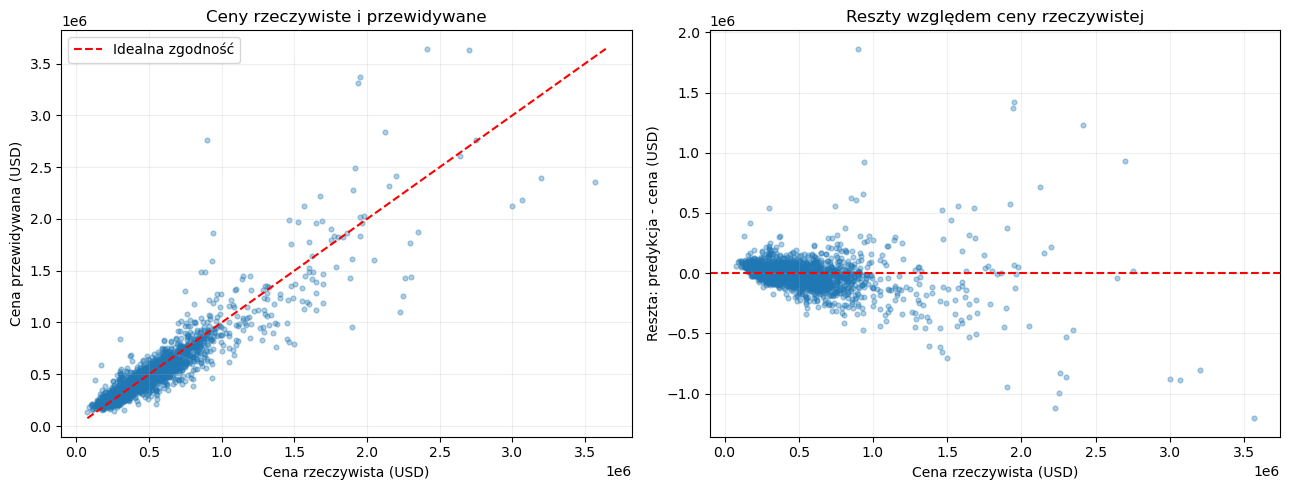


Mediana treningowa: 450000.0
90. percentyl treningowy: 885000.0

Błędy w grupach cenowych:


,Grupa,Liczebność,MAE,RMSE,Średnia reszta
0,Do mediany,1201,"42,427.03","60,977.15","11,533.64"
1,Mediana - P90,828,"80,243.36","109,616.69","-34,922.42"
2,Powyżej P90,191,"276,584.34","405,009.46","-84,040.84"



Pięć największych błędów bezwzględnych:


,id,price,predykcja,reszta,blad_bezwzgledny,bedrooms,bathrooms,sqft_living,grade,condition,waterfront,view,zipcode,lat,long
21050,2424059170,"900,000.00","2,763,368.37","1,863,368.37","1,863,368.37",5,6.00,7120,12,3,0,4,98006,47.55,-122.11
11871,8835800350,"1,950,000.00","3,375,103.97","1,425,103.97","1,425,103.97",4,3.25,7420,12,3,0,3,98045,47.45,-121.76
6501,2626069030,"1,940,000.00","3,312,728.84","1,372,728.84","1,372,728.84",4,5.75,7220,12,3,0,4,98053,47.71,-122.01
13411,2426039123,"2,415,000.00","3,643,769.26","1,228,769.26","1,228,769.26",5,4.75,7880,13,3,0,2,98177,47.73,-122.36
21576,9253900271,"3,567,000.00","2,361,807.13","-1,205,192.87","1,205,192.87",5,4.50,4850,10,3,1,4,98008,47.59,-122.11



Liczba przeszacowań: 966
Liczba niedoszacowań: 1254

Grupa z największym MAE:
Grupa: Powyżej P90
MAE: 276584.34
Średnia reszta: -84040.84
Liczebność: 191


In [7]:
y_true = val["price"].to_numpy(dtype=float)
y_pred = np.asarray(predykcje[najlepszy_model]["val"], dtype=float)

reszty = y_pred - y_true # reszta dodatnia oznacza przeszacowanie ceny
bledy_bezwzgledne = np.abs(reszty)

print("Model:", najlepszy_model)
print("MAE:", round(mean_absolute_error(y_true, y_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_true, y_pred)), 2))
print("Średnia reszta:", round(reszty.mean(), 2))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_true, y_pred, alpha=0.35, s=12)
min_cena = min(y_true.min(), y_pred.min())
max_cena = max(y_true.max(), y_pred.max())
ax[0].plot(
    [min_cena, max_cena],
    [min_cena, max_cena],
    "r--",
    label="Idealna zgodność"
)

ax[0].set_title("Ceny rzeczywiste i przewidywane")
ax[0].set_xlabel("Cena rzeczywista (USD)")
ax[0].set_ylabel("Cena przewidywana (USD)")
ax[0].legend()
ax[0].grid(alpha=0.2)

ax[1].scatter(y_true, reszty, alpha=0.35, s=12)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_title("Reszty względem ceny rzeczywistej")
ax[1].set_xlabel("Cena rzeczywista (USD)")
ax[1].set_ylabel("Reszta: predykcja - cena (USD)")
ax[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


# trzy grupy cenowe dla progow wyłącznie z treningu
mediana_train = train["price"].median()
p90_train = train["price"].quantile(0.90)

grupy = {
    "Do mediany": y_true <= mediana_train,
    "Mediana - P90": (y_true > mediana_train) & (y_true <= p90_train),
    "Powyżej P90": y_true > p90_train
}

wyniki_grup = []
for nazwa, maska in grupy.items():
    yt = y_true[maska]
    yp = y_pred[maska]
    e = reszty[maska]

    wyniki_grup.append({
        "Grupa": nazwa,
        "Liczebność": len(yt),
        "MAE": mean_absolute_error(yt, yp),
        "RMSE": np.sqrt(mean_squared_error(yt, yp)),
        "Średnia reszta": e.mean()
    })

tabela_grup = pd.DataFrame(wyniki_grup)

print("\nMediana treningowa:", round(mediana_train, 2))
print("90. percentyl treningowy:", round(p90_train, 2))
print("\nBłędy w grupach cenowych:")
display(tabela_grup.round(2))
assert tabela_grup["Liczebność"].sum() == len(val)


# pięć największych błędów bezwzględnych
analiza = val.copy()
analiza["predykcja"] = y_pred
analiza["reszta"] = reszty
analiza["blad_bezwzgledny"] = bledy_bezwzgledne

kolumny = [
    "id",
    "price",
    "predykcja",
    "reszta",
    "blad_bezwzgledny",
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "grade",
    "condition",
    "waterfront",
    "view",
    "zipcode",
    "lat",
    "long"
]

najwieksze_bledy = analiza.nlargest(5, "blad_bezwzgledny")[kolumny]
print("\nPięć największych błędów bezwzględnych:")
display(najwieksze_bledy.round(2))

#sytuacja wymagająca ostrożności
print("\nLiczba przeszacowań:", np.sum(reszty > 0))
print("Liczba niedoszacowań:", np.sum(reszty < 0))
najtrudniejsza_grupa = tabela_grup.loc[
    tabela_grup["MAE"].idxmax()
]

print("\nGrupa z największym MAE:")
print("Grupa:", najtrudniejsza_grupa["Grupa"])
print("MAE:", round(najtrudniejsza_grupa["MAE"], 2))
print("Średnia reszta:", round(najtrudniejsza_grupa["Średnia reszta"], 2))
print("Liczebność:", int(najtrudniejsza_grupa["Liczebność"]))

**Miejsce na wyprowadzenie, wyniki i interpretację:**

**Ogólna analiza błędów**

Dla wybranego modelu M5 na zbiorze walidacyjnym uzyskano MAE = 76 677,47 USD oraz RMSE = 143 547,26 USD. RMSE jest znacznie wyższe od MAE, co wskazuje na występowanie pojedynczych dużych błędów predykcji.

Średnia reszta wynosi −14 016,06 USD, co oznacza ogólną tendencję do niedoszacowywania cen. Model niedoszacował 1254 nieruchomości, a przeszacował 966. Na wykresach widać, że rozrzut predykcji i reszt zwiększa się wraz z ceną nieruchomości. Model jest mniej stabilny dla najdroższych domów.

**Błędy w grupach cenowych**

Grupy wyznaczono na podstawie mediany (450 000 USD) i 90. percentyla (885 000 USD) cen ze zbioru treningowego. 

Do mediany: 1201 nieruchomości, MAE = 42 427,03 USD, średnia reszta = +11 533,64 USD, czyli niewielka tendencja do przeszacowywania.

Od mediany do P90: 828 nieruchomości, MAE = 80 243,36 USD, średnia reszta = −34 922,42 USD, czyli istnieje tendencja do niedoszacowywania.

Powyżej P90: 191 nieruchomości, MAE = 276 584,34 USD, średnia reszta = −84 040,84 USD, czyli największe błędy i wyraźne niedoszacowywanie.

Największe MAE występuje w grupie najdroższych nieruchomości i jest około 6,5 razy wyższe niż w grupie najtańszej. Należy jednak pamiętać, że są to błędy bezwzględne w USD, a droższe nieruchomości naturalnie mogą generować większe odchylenia kwotowe.

**Pięć największych błędów**

Największy błąd wyniósł 1 863 368,37 USD; model przewidział około 2,76 mln USD zamiast rzeczywistych 900 tys. USD.

Cztery spośród pięciu największych błędów to przeszacowania. Dotyczą dużych domów o powierzchni mieszkalnej 7120–7880 stóp² i wysokiej klasie wykończenia (grade 12–13). Możliwe, że model przypisuje tym cechom zbyt duży wpływ na cenę.

Piąty przypadek to niedoszacowanie o 1 205 192,87 USD nieruchomości sprzedanej za 3,567 mln USD. Dom ma dostęp do wody (waterfront = 1) i wysoką ocenę widoku (view = 4), co może wskazywać na trudność w dokładnym uwzględnieniu szczególnie atrakcyjnych lokalizacji.

Warto zaznaczyc, że są to możliwe wyjaśnienia, a nie potwierdzone przyczyny błędów.

**Ograniczenia zaufania do modelu**

Szczególną ostrożność należy zachować przy wycenie nieruchomości luksusowych, zwłaszcza bardzo dużych domów i obiektów z dostępem do wody. W tej grupie błędy mogą przekraczać milion dolarów. W dalszej analizie warto sprawdzić liczbę podobnych nieruchomości w treningu oraz porównać ich rzeczywiste ceny i cechy. Pozwoliłoby to ocenić, czy duże błędy wynikają z niewielkiej reprezentacji takich obiektów, nietypowych transakcji czy ograniczeń modelu liniowego.

**Wniosek końcowy**

M5 osiąga najlepszą jakość spośród porównanych modeli, ale jego dokładność zależy od przedziału cenowego. Największe ryzyko błędnej wyceny dotyczy drogich i nietypowych nieruchomości, dlatego predykcje dla takich obiektów wymagają dodatkowej weryfikacji.

### 7. Zadanie 5 — klasyfikacja SVM

Wyznacz q jako 75. percentyl ceny w treningu po podziale id, przed ewentualnym usuwaniem odstających przykładów. Definicja klasy: y_cls = 1, gdy price > q; w przeciwnym razie 0. Ten sam q stosuj we wszystkich częściach. Cena służy wyłącznie do zdefiniowania etykiety.

Zastosuj bazowe cechy z zadania 3. Wytrenuj SVC(kernel='linear') dla C w {0.1, 1, 10} oraz SVC(kernel='rbf') dla C w {0.1, 1, 10} i gamma w {0.01, 0.1}. Łącznie 9 konfiguracji. Aby ograniczyć czas, wolno wykorzystać wspólny dla obu jąder, stratyfikowany podzbiór maksymalnie 5000 przykładów treningowych, wylosowany z random_state równym numerowi indeksu. Podzbiór jest zalecany. Skalowanie, uzupełnianie braków i kategorie dopasuj tylko na tym podzbiorze. Walidacja pozostaje pełna. Nie trzeba trenować klasyfikatorów na GPU.

Wybierz jedną konfigurację według największego ROC AUC na walidacji; przy dokładnym remisie wybierz kolejno jądro liniowe, mniejsze C, mniejsze gamma. Dla zwycięzcy pokaż macierz pomyłek, precision, recall, F1, accuracy i krzywą ROC. ROC i AUC licz z decision_function, pozostałe miary z predict przy standardowym progu. Podaj liczebności klas i accuracy klasyfikatora zawsze wybierającego większościową klasę treningową. Nie ma wymogu strojenia progu ani kalibracji prawdopodobieństw.

Wyjaśnij wpływ C, gamma i skalowania oraz dlaczego AUC nie jest procentem poprawnych etykiet. Dla p>2 nie jest wymagany wykres granicy decyzyjnej.

Próg q (75. percentyl treningu): 648000.0

Klasy w pełnym treningu:
price
0    10876
1     3621
Name: count, dtype: int64

Klasy w walidacji:
price
0    1746
1     474
Name: count, dtype: int64

Liczebność podzbioru: 5000
Klasy w podzbiorze:
0    3751
1    1249
Name: count, dtype: int64

Wyniki wszystkich konfiguracji:


,kernel,C,gamma,ROC_AUC
0,linear,0.10,NaN,0.97
1,linear,1.00,NaN,0.97
2,linear,10.00,NaN,0.97
3,rbf,0.10,0.01,0.94
4,rbf,0.10,0.10,0.95
5,rbf,1.00,0.01,0.96
6,rbf,1.00,0.10,0.97
7,rbf,10.00,0.01,0.97
8,rbf,10.00,0.10,0.96



Najlepsza konfiguracja:
Jądro: linear
C: 10.0
gamma: None
ROC AUC: 0.9736

Metryki najlepszego modelu:


,Precision,Recall,F1,Accuracy,ROC AUC
0,0.86,0.80,0.83,0.93,0.97



Klasa większościowa treningu: 0
Accuracy klasyfikatora większościowego: 0.7865
Accuracy najlepszego SVM: 0.9288


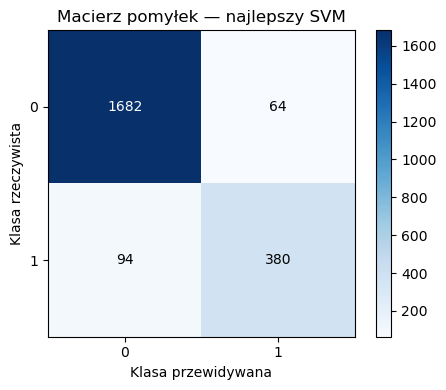

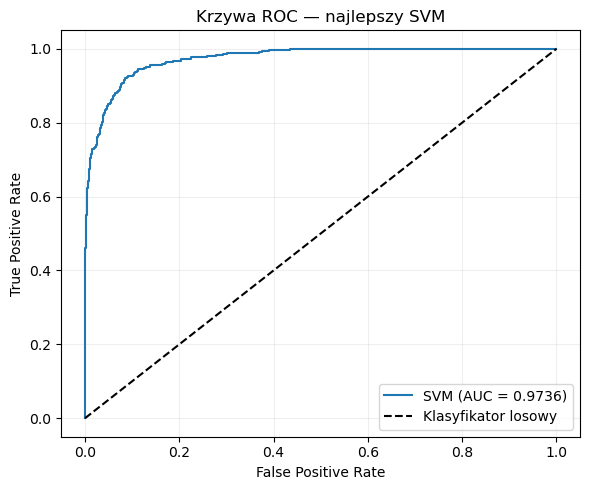

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix,
    precision_score, recall_score, f1_score, accuracy_score
)

q = float(train["price"].quantile(0.75))
y_cls_train = (train["price"] > q).astype(int)
y_cls_val = (val["price"] > q).astype(int)
print("Próg q (75. percentyl treningu):", q)
print("\nKlasy w pełnym treningu:")
print(y_cls_train.value_counts().sort_index())
print("\nKlasy w walidacji:")
print(y_cls_val.value_counts().sort_index())

#jeden wspólny i stratyfikowany podzbiór treningowy
indeksy = np.arange(len(train))
if len(train) > 5000:
    indeksy_sub, _ = train_test_split(
        indeksy,
        train_size=5000,
        stratify=y_cls_train,
        random_state=NR_INDEKSU
    )
else:
    indeksy_sub = indeksy

train_svm = train.iloc[indeksy_sub].copy()
y_sub = y_cls_train.iloc[indeksy_sub].to_numpy()
print("\nLiczebność podzbioru:", len(train_svm))
print("Klasy w podzbiorze:")
print(pd.Series(y_sub).value_counts().sort_index())


# preprocessing dopasowany tylko na podzbiorze
train_svm_model = popraw_lata(train_svm) # funkcja z zad3
val_svm_model = popraw_lata(val)
X_sub, X_val_svm, nazwy_svm, scaler_svm = przygotuj_dane(
    train_svm_model,
    val_svm_model,
    cechy_bazowe
)

y_val_svm = y_cls_val.to_numpy()
assert len(X_sub) == len(y_sub)
assert len(X_val_svm) == len(y_val_svm)
assert X_sub.shape[1] == X_val_svm.shape[1]

konfiguracje = []
for C in [0.1, 1, 10]:
    konfiguracje.append(("linear", C, None))

for C in [0.1, 1, 10]:
    for gamma in [0.01, 0.1]:
        konfiguracje.append(("rbf", C, gamma))

wyniki_svm = []
modele_svm = {}

for kernel, C, gamma in konfiguracje:
    if kernel == "linear":
        model = SVC(kernel="linear", C=C)
    else:
        model = SVC(kernel="rbf", C=C, gamma=gamma)

    model.fit(X_sub, y_sub)
    oceny = model.decision_function(X_val_svm)
    auc = roc_auc_score(y_val_svm, oceny)
    klucz = (kernel, C, gamma)
    modele_svm[klucz] = model
    wyniki_svm.append({
        "kernel": kernel,
        "C": C,
        "gamma": gamma,
        "ROC_AUC": auc
    })

tabela_svm = pd.DataFrame(wyniki_svm)
assert len(tabela_svm) == 9

print("\nWyniki wszystkich konfiguracji:")
display(tabela_svm.round(4))

# wybór największego AUC
tabela_ranking = tabela_svm.copy()
tabela_ranking["kolejnosc_jadra"] = (tabela_ranking["kernel"].map({"linear": 0, "rbf": 1}))
tabela_ranking["gamma_sort"] = tabela_ranking["gamma"].fillna(0)
tabela_ranking = tabela_ranking.sort_values(
    ["ROC_AUC", "kolejnosc_jadra", "C", "gamma_sort"],
    ascending=[False, True, True, True],
    kind="stable"
)

najlepszy = tabela_ranking.iloc[0]
kernel_best = najlepszy["kernel"]
C_best = float(najlepszy["C"])
gamma_best = (
    None if pd.isna(najlepszy["gamma"])
    else float(najlepszy["gamma"])
)

model_best = modele_svm[(kernel_best, C_best, gamma_best)]
print("\nNajlepsza konfiguracja:")
print("Jądro:", kernel_best)
print("C:", C_best)
print("gamma:", gamma_best)
print("ROC AUC:", round(najlepszy["ROC_AUC"], 4))

# predykcje i wymagane metryki
pred_best = model_best.predict(X_val_svm)
oceny_best = model_best.decision_function(X_val_svm)
metryki_svm = {
    "Precision": precision_score(y_val_svm, pred_best, zero_division=0),
    "Recall": recall_score(y_val_svm, pred_best, zero_division=0),
    "F1": f1_score(y_val_svm, pred_best, zero_division=0),
    "Accuracy": accuracy_score(y_val_svm, pred_best),
    "ROC AUC": roc_auc_score(y_val_svm, oceny_best)
}

print("\nMetryki najlepszego modelu:")
display(pd.DataFrame([metryki_svm]).round(4))

# klasyfikator większościowy z pełnego treningu
klasa_wiekszosciowa = int(y_cls_train.value_counts().idxmax())
pred_wiekszosc = np.full(
    len(y_val_svm),
    klasa_wiekszosciowa,
    dtype=int
)
accuracy_wiekszosc = accuracy_score(y_val_svm, pred_wiekszosc)

print("\nKlasa większościowa treningu:", klasa_wiekszosciowa)
print("Accuracy klasyfikatora większościowego:",
      round(accuracy_wiekszosc, 4))
print("Accuracy najlepszego SVM:",
      round(metryki_svm["Accuracy"], 4))

cm = confusion_matrix(y_val_svm, pred_best, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black"
        )

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["0", "1"])
ax.set_yticklabels(["0", "1"])
ax.set_xlabel("Klasa przewidywana")
ax.set_ylabel("Klasa rzeczywista")
ax.set_title("Macierz pomyłek — najlepszy SVM")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

# krzywa ROC z decision_function
fpr, tpr, progi = roc_curve(y_val_svm, oceny_best)
plt.figure(figsize=(6, 5))
plt.plot(
    fpr, tpr,
    label=f"SVM (AUC = {metryki_svm['ROC AUC']:.4f})"
)
plt.plot([0, 1], [0, 1], "k--", label="Klasyfikator losowy")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Krzywa ROC — najlepszy SVM")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Miejsce na wyprowadzenie, wyniki i interpretację:**

**Przygotowanie danych i definicja klas**

Zadanie polegało na klasyfikacji nieruchomości na dwie klasy: 0 (cena nieprzekraczająca 648 000 USD) oarz 1 (cena powyżej 648 000 USD). Próg ustalono jako 75. percentyl cen w zbiorze treningowym, bez wykorzystania walidacji. Do uczenia SVM wylosowano jeden stratyfikowany podzbiór 5000 obserwacji (3751 klasy 0 i 1249 klasy 1), zachowując proporcje klas. Wszystkie konfiguracje trenowano na tym samym podzbiorze i oceniano na pełnej walidacji (2220 obserwacji).

Zastosowano cechy bazowe z zadania 3. Przygotowanie danych, w tym uzupełnianie braków, kodowanie zipcode i skalowanie cech liczbowych, dopasowano wyłącznie na podzbiorze treningowym.

**Metoda SVM i strojenie parametrów**

Porównano 9 konfiguracji SVM: 3 z jądrem liniowym oraz 6 z jądrem RBF. 

- C kontroluje karę za błędną klasyfikację. Małe C oznacza silniejszą regularyzację, a duże C większy nacisk na poprawne rozdzielenie obserwacji treningowych.
- Gamma określa zasięg wpływu obserwacji w jądrze RBF. Mała gamma prowadzi do gładszej granicy decyzyjnej, a większa pozwala modelowi uwzględniać bardziej lokalne zależności.
- Skalowanie jest ważne, ponieważ SVM opiera się na odległościach i iloczynach skalarnych. Bez niego cechy o dużych wartościach mogłyby nadmiernie wpływać na model.

Konfiguracje porównano za pomocą ROC AUC, obliczanego z wartości decision_function, a nie z przewidzianych etykiet klas. ROC AUC mierzy zdolność modelu do rozróżniania klas niezależnie od konkretnego progu decyzyjnego.

**Wybór najlepszego modelu**

Najlepszy wynik uzyskał SVM z jądrem liniowym, C = 10, osiągając ROC AUC = 0,9736. Wysokie AUC oznacza, że model bardzo dobrze porządkuje nieruchomości według prawdopodobnej przynależności do klasy droższych domów. Warianty RBF również osiągały wysokie wyniki, ale nie przewyższyły najlepszego modelu liniowego.

**Interpretacja metryk i macierzy pomyłek**

Dla najlepszego SVM uzyskano: Precision = 0,856; Recall = 0,802; F1 = 0,828; Accuracy = 0,9288; ROC AUC = 0,9736.

Macierz pomyłek: TN = 1682 (poprawnie rozpoznane nieruchomości z kalsy 0); FP = 64 (nieruchomości błędnie zaklasyfikowane jako drogie); FN = 94 (drogie nieruchomości błędnie zaklasyfikowane do klasy 0); TP = 380 (poprawnie rozpoznane drogie wartości nieruchomości do klasy 1).

Precision ≈ 85,6% oznacza, że spośród nieruchomości zaklasyfikowanych jako drogie około 85,6% rzeczywiście należało do klasy 1. Recall ≈ 80,2% oznacza, że model wykrył około 80,2% wszystkich drogich nieruchomości, pomijając pozostałe 19,8%. F1 ≈ 82,8% wskazuje na dobry kompromis między precision i recall.

**Porównanie z klasyfikatorem większościowym**

Klasyfikator zawsze przewidujący klasę 0 uzyskał accuracy = 78,65%, natomiast najlepszy SVM osiągnął 92,88%. Oznacza to poprawę o 14,23 punktu procentowego. Model SVM nie tylko wykorzystuje przewagę liczebną klasy 0, ale również skutecznie identyfikuje większość nieruchomości z klasy 1.

**Interpretacja krzywej ROC**

Krzywa ROC przebiega blisko lewego górnego rogu wykresu, wyraźnie powyżej przekątnej odpowiadającej klasyfikatorowi losowemu. Potwierdza to wysoką zdolność rozróżniania obu klas (AUC = 0,9736).

**Wniosek końcowy**

Najlepszym klasyfikatorem okazał się liniowy SVM z C = 10. Uzyskał wysoką skuteczność klasyfikacji (92,88%) i bardzo dobrą zdolność rozróżniania klas (ROC AUC = 0,9736). Wyniki wskazują, że zastosowane cechy dobrze opisują różnice między tańszymi i droższymi nieruchomościami. Głównym ograniczeniem pozostaje pomijanie części drogich domów tj 94 z 474 przypadków klasy 1.

### 8. Zadanie 6 — eksperyment indywidualny

Wariant = numer indeksu modulo 4. Badamy ustalony Ridge M2 na treningu i pełnej walidacji. Nie zmieniaj głównego modelu końcowego na podstawie tego dodatkowego eksperymentu; to oddzielne badanie diagnostyczne. Pokaż hipotezę, kontrolowane porównanie, wynik liczbowy i wyjaśnienie. Wymagane scenariusze:

| Wariant | Eksperyment |
|---|---|
| 0 | Pomnóż sqft_living przez 100 zarówno w treningu, jak i walidacji. Porównaj przed/po zmianie przy poprawnie dopasowanym skalowaniu oraz przed/po bez skalowania. Cztery dopasowania, ta sama lambda. Sprawdź zbieżność; wynik źle zbieżnego GD nie dowodzi efektu regularyzacji. |
| 1 | Dodaj dokładną kopię jednej niestałej liczbowej kolumny po przygotowaniu i skalowaniu cech. Porównaj predykcje i współczynniki OLS, Ridge i Lasso przed/po. Wybrane wcześniej parametry bez zmian. |
| 2 | Z treningu usuń transakcje powyżej 99. percentyla ceny treningowej. Ponownie dopasuj preprocessing i Ridge przy tej samej lambda. Walidacja pozostaje kompletna. Porównaj MAE, RMSE oraz błędy najdroższej grupy. |
| 3 | Usuń zipcode, lat, long i wszystkie ich pochodne. Ponownie dopasuj preprocessing i Ridge przy tej samej lambda. Porównaj błędy ogólne i dla trzech najliczniejszych kodów pocztowych treningu; podaj liczebności walidacyjne. |

Przy wariancie 0 do kontroli można użyć własnego rozwiązania równań normalnych. Należy nadal wykonać główne zadanie 2 metodą gradientową. Wynik negatywny lub bardzo mała zmiana są pełnoprawnym wynikiem, jeśli zostały poprawnie wyjaśnione.

In [9]:
prog_p99 = train["price"].quantile(0.99)
train_bez_top1 = train.loc[train["price"] <= prog_p99].copy()
print("Próg P99:", round(prog_p99, 2))
print("Liczba obserwacji przed:", len(train))
print("Liczba obserwacji po:", len(train_bez_top1))
print("Liczba usuniętych:", len(train) - len(train_bez_top1))
print("Liczba obserwacji walidacyjnych:", len(val))

train_bez_top1_model = popraw_lata(train_bez_top1) # ponowne przygotowywanie danych
val_zad6_model = popraw_lata(val)

X_tr_zad6, X_val_zad6, nazwy_zad6, scaler_zad6 = przygotuj_dane(
    train_bez_top1_model,
    val_zad6_model,
    cechy_bazowe
)

# cel skalowany według zmniejszonego treningu
y_tr_zad6 = train_bez_top1["price"].to_numpy(dtype=float)
srednia_zad6 = y_tr_zad6.mean()
skala_zad6 = y_tr_zad6.std()
y_tr_zad6_scaled = (y_tr_zad6 - srednia_zad6) / skala_zad6


# ponowne uczenie Ridge dla tej samej lambda
model_zad6 = ucz_ridge(
    X_tr_zad6,
    y_tr_zad6_scaled,
    lambda_m2
)

# odwrócenie skalowania celu do USD
pred_zad6 = (model_zad6.predict(X_val_zad6) * skala_zad6 + srednia_zad6)

# oryginalny M2
pred_m2 = np.asarray(predykcje["M2"]["val"], dtype=float)
y_val_zad6 = val["price"].to_numpy(dtype=float)

# porównanie MAE i RMSE na pełnej walidacji
met_m2 = regression_metrics(y_val_zad6, pred_m2)
met_zad6 = regression_metrics(y_val_zad6, pred_zad6)
porownanie_zad6 = pd.DataFrame([
    {
        "Model": "M2 oryginalny",
        "MAE": met_m2["MAE"],
        "RMSE": met_m2["RMSE"]
    },
    {
        "Model": "M2 bez top 1% treningu",
        "MAE": met_zad6["MAE"],
        "RMSE": met_zad6["RMSE"]
    }
])

print("\nPorównanie na pełnej walidacji:")
display(porownanie_zad6.round(2))

print("Zmiana MAE:", round(met_zad6["MAE"] - met_m2["MAE"], 2))
print("Zmiana RMSE:", round(met_zad6["RMSE"] - met_m2["RMSE"], 2))


# próg P90 z pełnego treningu (najdroższe nieruchomości)
prog_p90 = train["price"].quantile(0.90)
maska_drogie = y_val_zad6 > prog_p90
y_drogie = y_val_zad6[maska_drogie]
porownanie_drogie = pd.DataFrame([
    {
        "Model": "M2 oryginalny",
        "Liczebność": len(y_drogie),
        "MAE": mean_absolute_error(y_drogie, pred_m2[maska_drogie]),
        "RMSE": np.sqrt(mean_squared_error(y_drogie, pred_m2[maska_drogie]))
    },
    {
        "Model": "M2 bez top 1% treningu",
        "Liczebność": len(y_drogie),
        "MAE": mean_absolute_error(y_drogie, pred_zad6[maska_drogie]),
        "RMSE": np.sqrt(mean_squared_error(y_drogie, pred_zad6[maska_drogie]))
    }
])

print("\nNajdroższa grupa (ceny powyżej P90):")
print("Próg P90:", round(prog_p90, 2))
display(porownanie_drogie.round(2))


#sprawdzenie warunków eksperymentu
assert len(pred_m2) == len(val)
assert len(pred_zad6) == len(val)
assert len(train_bez_top1) < len(train)
assert model_zad6.lam == lambda_m2
print("\nLambda bez zmian:", lambda_m2)
print("Liczba cech przed:", len(nazwy_bazowe))
print("Liczba cech po:", len(nazwy_zad6))
print("Iteracje nowego RidgeGD:", model_zad6.n_iter_)
print("Powód zatrzymania:", model_zad6.stop_reason_)

Próg P99: 1959248.8
Liczba obserwacji przed: 14497
Liczba obserwacji po: 14352
Liczba usuniętych: 145
Liczba obserwacji walidacyjnych: 2220

Porównanie na pełnej walidacji:


,Model,MAE,RMSE
0,M2 oryginalny,"97,176.39","152,307.11"
1,M2 bez top 1% treningu,"88,335.40","155,194.85"


Zmiana MAE: -8840.99
Zmiana RMSE: 2887.74

Najdroższa grupa (ceny powyżej P90):
Próg P90: 885000.0


,Model,Liczebność,MAE,RMSE
0,M2 oryginalny,191,"243,109.51","361,215.17"
1,M2 bez top 1% treningu,191,"302,101.27","434,874.21"



Lambda bez zmian: 0.0001
Liczba cech przed: 87
Liczba cech po: 87
Iteracje nowego RidgeGD: 30000
Powód zatrzymania: max_iter


**Miejsce na wyprowadzenie, wyniki i interpretację:**

**Hipoteza przed wykonanie** Usunięcie z treningu 1% najdroższych transakcji może poprawić MAE dla typowych nieruchomości, ale pogorszyć przewidywania dla najdroższej grupy, ponieważ model będzie miał mniej przykładów wysokich cen. 

Porównujemy ustalony Ridge M2 przed i po usunięciu obserwacji. Zachowujemy tę samą wartość $\lambda$, pełną walidację i identyczny sposób oceny. Ponownie dopasowujemy preprocessing wyłącznie na zmniejszonym treningu.

**Przebieg eksperymentu**

Próg 99. percentyla ceny treningowej wyniósł 1 959 248,80 USD. Usunięto 145 obserwacji, zmniejszając trening z 14 497 do 14 352 nieruchomości. Ponownie dopasowano preprocessing i wytrenowano Ridge M2 z niezmienionym $\lambda=0{,}0001$. Walidacja pozostała kompletna (2220 obserwacji). Wyniki na pełnej walidacji:

- MAE zmniejszyło się z 97 176,39 do 88 335,40 USD, czyli o 8840,99 USD (9,1%).
- RMSE wzrosło z 152 307,11 do 155 194,85 USD, czyli o 2887,74 USD (1,9%).

Spadek MAE oznacza mniejszy przeciętny błąd bezwzględny, natomiast wzrost RMSE wskazuje, że większe błędy mają silniejszy wpływ na ocenę zmodyfikowanego modelu.

**Wyniki dla najdroższej grupy (cena powyżej 885 000 USD, 191 obserwacji)**

Usunięcie najdroższych przykładów z treningu wyraźnie pogorszyło jakość przewidywania wysokich cen.

- MAE wzrosło z 243 109,51 do 302 101,27 USD o 58 991,76 USD (24,3%).
- RMSE wzrosło z 361 215,17 do 434 874,21 USD o 73 659,04 USD (20,4%).

**Weryfikacja hipotezy** 

Hipoteza została częściowo potwierdzona. Potwierdzono poprawę MAE na pełnej walidacji oraz pogorszenie wyników dla najdroższej grupy. Nie sprawdzono jednak osobno MAE typowych nieruchomości, więc nie można jednoznacznie stwierdzić, że właśnie w tej grupie nastąpiła poprawa.

**Wniosek** 

Najdroższe transakcje wpływają na dopasowanie Ridge M2. Ich usunięcie poprawia przeciętny błąd bezwzględny na całej walidacji, ale ogranicza dokładność wycen drogich nieruchomości. Eksperyment ma charakter diagnostyczny i nie zmienia wcześniej wybranego modelu końcowego M5.

### 9. Zamknięcie analizy i test

Zapisz ostateczną konfigurację regresji oraz SVM, listę cech, parametry transformacji i kryterium wyboru. Dla prostoty i jednoznaczności w tym projekcie nie douczaj modeli na treningu połączonym z walidacją. Oceniaj na teście te same dopasowane modele, które wybrałeś na walidacji.

W jednej końcowej sekcji policz na pełnym teście metryki modelu regresyjnego i medianowego M0 oraz metryki wybranego SVM i klasyfikatora większościowego. Możesz także pokazać z góry zdefiniowane grupy cenowe. Nie stroisz już niczego po tych wynikach. Samo ponowne wykonanie niezmienionego notebooka nie narusza tej zasady. Nie wykorzystuj testu w zadaniu indywidualnym ani w zmianach wykonywanych podczas obrony.

Zakończ odpowiedzią: które hipotezy potwierdziły się, jakie są ograniczenia rozwiązania i czego wymagałoby zastosowanie go do nowych danych. Odwołuj się do własnych tabel i wykresów. Nie używaj ogólnego komentarza niezwiązanego z wynikami.

**Zamknięcie konfiguracji przed testem**

**Regresja** wybrano M5, czyli własny RidgeGD z regularyzacją $\lambda=0{,}0001$, cechami bazowymi oraz trzema dodatkowymi cechami: wiek_domu, udzial_piwnicy, ile_sypialni_na_lazienke. Cel stanowi standaryzowany $\log(price)$. Predykcje przeliczane są do USD przez odwrócenie standaryzacji i funkcję wykładniczą. Model wybrano według najniższego MAE walidacyjnego (76 677,47 USD).

**Klasyfikacja** wybrano liniowy SVM z $C=10$, bez parametru gamma, na cechach bazowych. Model uczono na stratyfikowanym podzbiorze 5000 obserwacji, przy progu klasy 1 równym 648 000 USD (75. percentyl treningu). Kryterium wyboru stanowiło najwyższe ROC AUC na pełnej walidacji (0,9736).

Nie łączono treningu z walidacją. Do testu wykorzystano dokładnie te same wytrenowane modele i parametry transformacji. Wyniki testowe służą wyłącznie końcowej ocenie.

In [10]:
# odtworzenie preprocessingu dla nowych danych
def transformuj_test(dane, trening_ref, cechy, nazwy, scaler):
    X = dane[cechy].copy()
    X_ref = trening_ref[cechy].copy()
    cat_cols = ["zipcode"] if "zipcode" in cechy else []
    cat_cols += [
        c for c in cechy
        if c not in cat_cols and
        not pd.api.types.is_numeric_dtype(X_ref[c])
    ]
    num_cols = [c for c in cechy if c not in cat_cols]
    mediany = X_ref[num_cols].median().fillna(0) #te same mediany co przy wcześniejszym przygotowaniu treningu
    X[num_cols] = X[num_cols].fillna(mediany)
    for c in cat_cols:
        X[c] = X[c].astype("string").fillna("BRAK")

    X = pd.get_dummies(X, columns=cat_cols, dtype=float)
    X = X.reindex(columns=nazwy, fill_value=0) #ten sam układ kolumn co podczas uczenia
    X[num_cols] = scaler.transform(X[num_cols]) # skalowanie wcześniej dopasowanym obiektem
    return X.to_numpy(dtype=float)

assert najlepszy_model == "M5"
assert kernel_best == "linear"
assert C_best == 10.0
m5_test = modele["M5"]
svm_test = model_best
assert np.isclose(m5_test.lam, lambda_m5) # sprawdzennie spójności zapisanych konfiguracji
assert svm_test.kernel == kernel_best
assert np.isclose(svm_test.C, C_best)

# te same poprawki dla danych testowych
test_model = popraw_lata(test)
test_plus = dodaj_cechy(test_model)
X_test_m5 = transformuj_test(
    test_plus,
    train_plus,
    cechy_rozszerzone,
    nazwy_plus,
    scaler_plus
)

X_test_svm = transformuj_test(
    test_model,
    train_svm_model,
    cechy_bazowe,
    nazwy_svm,
    scaler_svm
)

assert X_test_m5.shape[1] == X_train_plus.shape[1]
assert X_test_svm.shape[1] == X_sub.shape[1]


# regresja dla M5 i mediana M0
y_test = test["price"].to_numpy(dtype=float)
pred_test_m5 = np.exp(
    m5_test.predict(X_test_m5) * skala_log + srednia_log
)

pred_test_m0 = np.full(
    len(test),
    modele["M0"],
    dtype=float
)

met_m5 = regression_metrics(y_test, pred_test_m5)
met_m0 = regression_metrics(y_test, pred_test_m0)
tabela_test_reg = pd.DataFrame([
    {"Model": "M0", **met_m0},
    {"Model": "M5", **met_m5}
])

print("Regresja (pełny test):")
display(tabela_test_reg.round(2))

# klasyfikacja dla SVM i klasa większościowa
y_test_cls = (test["price"] > q).astype(int).to_numpy()
pred_test_svm = svm_test.predict(X_test_svm)
oceny_test_svm = svm_test.decision_function(X_test_svm)
pred_test_wiekszosc = np.full(
    len(test),
    klasa_wiekszosciowa,
    dtype=int
)

def metryki_klasyfikacji(y_true, y_pred, oceny=None):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": (
            roc_auc_score(y_true, oceny)
            if oceny is not None else np.nan
        )
    }

tabela_test_cls = pd.DataFrame([
    {
        "Model": "Większościowy",
        **metryki_klasyfikacji(y_test_cls, pred_test_wiekszosc)
    },
    {
        "Model": "SVM",
        **metryki_klasyfikacji(
            y_test_cls, pred_test_svm, oceny_test_svm
        )
    }
])

print("\nKlasyfikacja (pełny test):")
display(tabela_test_cls.round(4))
print("\nMacierz pomyłek SVM:")
display(pd.DataFrame(
    confusion_matrix(y_test_cls, pred_test_svm, labels=[0, 1]),
    index=["Rzeczywista 0", "Rzeczywista 1"],
    columns=["Przewidziana 0", "Przewidziana 1"]
))


# porównanie walidacji z testem
porownanie_reg = pd.DataFrame([
    {
        "Zbiór": "Walidacja",
        "MAE": mean_absolute_error(
            y_val, predykcje["M5"]["val"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_val, predykcje["M5"]["val"]
        ))
    },
    {
        "Zbiór": "Test",
        "MAE": met_m5["MAE"],
        "RMSE": met_m5["RMSE"]
    }
])
porownanie_cls = pd.DataFrame([
    {
        "Zbiór": "Walidacja",
        "Accuracy": accuracy_score(y_val_svm, pred_best),
        "ROC_AUC": roc_auc_score(y_val_svm, oceny_best)
    },
    {
        "Zbiór": "Test",
        "Accuracy": accuracy_score(y_test_cls, pred_test_svm),
        "ROC_AUC": roc_auc_score(y_test_cls, oceny_test_svm)
    }
])
print("\nWalidacja i test dla M5:")
display(porownanie_reg.round(2))
print("\nWalidacja i test dla SVM:")
display(porownanie_cls.round(4))
print("\nLiczebność testu:", len(test))
print("Liczba cech M5:", len(nazwy_plus))
print("Liczba cech SVM:", len(nazwy_svm))
print("Lambda M5:", lambda_m5)
print("SVM:", kernel_best, "| C =", C_best)
print("Próg klasyfikacji:", q)

Regresja (pełny test):


,Model,MAE,RMSE,R2
0,M0,"226,474.51","385,013.67",-0.08
1,M5,"85,368.15","145,058.06",0.85



Klasyfikacja (pełny test):


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Większościowy,0.74,0.00,0.00,0.00,NaN
1,SVM,0.91,0.91,0.72,0.81,0.97



Macierz pomyłek SVM:


,Przewidziana 0,Przewidziana 1
Rzeczywista 0,3418,89
Rzeczywista 1,343,902



Walidacja i test dla M5:


,Zbiór,MAE,RMSE
0,Walidacja,"76,677.47","143,547.26"
1,Test,"85,368.15","145,058.06"



Walidacja i test dla SVM:


,Zbiór,Accuracy,ROC_AUC
0,Walidacja,0.93,0.97
1,Test,0.91,0.97



Liczebność testu: 4752
Liczba cech M5: 90
Liczba cech SVM: 87
Lambda M5: 0.0001
SVM: linear | C = 10.0
Próg klasyfikacji: 648000.0


- **Miejsce na wyprowadzenie, wyniki i interpretację:**

**Zamknięcie konfiguracji**

Do oceny testowej wykorzystano modele wybrane wcześniej na podstawie walidacji, bez ponownego trenowania ani strojenia:

- Regresja: M5 z własnym RidgeGD, $\lambda=0{,}0001$, 90 cech po uwzględnieniu trzech cech dodatkowych oraz transformacja $\log(price)$. Kryterium wyboru to najniższe MAE walidacyjne.

- Klasyfikacja: liniowy SVM, $C=10$, 87 cech bazowych, próg klasy 1 równy 648 000 USD. Kryterium wyboru to najwyższe ROC AUC walidacyjne.

Oba modele oceniono na pełnym zbiorze testowym obejmującym 4752 transakcje. Do porównań zastosowano również model medianowy M0 i klasyfikator większościowy.

**Regresja (wyniki na teście)**

M5 zmniejszył MAE względem M0 o 141 106,36 USD (62,3%). Wartość $R^2=0{,}85$ oznacza, że model wyjaśnia około 85% zmienności cen w zbiorze testowym. Na walidacji M5 uzyskał MAE = 76 677,47 USD i RMSE = 143 547,26 USD. Na teście MAE wzrosło o 8690,68 USD (11,3%), natomiast RMSE o 1510,80 USD (1,1%). Wyniki wskazują na umiarkowane pogorszenie dokładności na późniejszych danych, ale model zachowuje wyraźną przewagę nad punktem odniesienia M0.

**Klasyfikacja (wyniki na teście)**

Macierz pomyłek SVM: TN = 3418 (poprawnie rozpoznane nieruchomości z klasy 0); FP = 89 (tańsze nieruchomości błędnie uznane za drogie); FN = 343 (drogie nieruchomości błędnie przypisane do klasy 0); TP = 902 (poprawnie rozpoznane drogie nieruchomości).

SVM osiągnął accuracy około 90,91%, podczas gdy klasyfikator większościowy uzyskał około 73,80%. Precision wyniosło około 91,0%, co oznacza, że większość nieruchomości wskazanych przez model jako drogie rzeczywiście przekraczała próg 648 000 USD. Recall wyniosło około 72,4%. Model nie wykrył 343 spośród 1245 drogich nieruchomości, co stanowi jego istotne ograniczenie.

**Porównanie walidacji i testu**

Accuracy SVM zmniejszyło się z 92,88% do około 90,91%, natomiast ROC AUC pozostało na poziomie około 0,97. Wynika z tego, że zdolność rozróżniania klas utrzymała się na wysokim poziomie, choć skuteczność przy przyjętym progu decyzyjnym nieco spadła.

**Wniosek końcowy**

Oba modele zachowały dobrą jakość na niezależnym zbiorze testowym. M5 zdecydowanie przewyższył regresję medianową, a liniowy SVM klasyfikator większościowy. Wyniki potwierdzają przydatność zastosowanych cech i metod, ale wskazują również na ograniczenia: większe błędy wyceny drogich nieruchomości oraz pomijanie części drogich domów przez SVM.

Ocena testowa była tylko i wyłącznie końcowa tzn uzyskanych wyników nie wykorzystałam do strojenia ani zmiany modeli.

- **Podsumowanie do około 800 słów:** 

**Cel i przygotowanie danych**

Celem projektu było zbadanie możliwości przewidywania cen nieruchomości oraz klasyfikowania ich do grup cenowych na podstawie cech opisowych. Analizę przeprowadzono na zbiorze 21 613 transakcji nieruchomości. Dane podzielono chronologicznie na trening (14 497 obserwacji), walidację (2220) i test (4752), kontrolując brak wspólnych identyfikatorów nieruchomości między zbiorami. Taki podział pozwolił ocenić modele na transakcjach późniejszych niż dane treningowe.

Podczas kontroli jakości danych wykryto m.in. zerowe liczby sypialni i łazienek oraz lata budowy lub renowacji późniejsze od daty sprzedaży. Nie usuwano nietypowych transakcji. Niewiarygodne daty zastępowano brakami, a brakujące wartości liczbowe uzupełniano medianami wyznaczonymi na treningu. Kod pocztowy potraktowano jako zmienną kategoryczną i zakodowano metodą one-hot. Skalowanie i pozostałe operacje przygotowania danych dopasowywano bez wykorzystania walidacji ani testu.

**Implementacja i porównanie modeli regresyjnych**

W zadaniu 2 zaimplementowano własną regresję Ridge metodą spadku gradientowego. Poprawność gradientu zweryfikowano numerycznie, a predykcje porównano z rozwiązaniem równań normalnych. Zbadano również wpływ długości kroku na stabilność i szybkość optymalizacji.

Następnie porównano siedem modeli regresyjnych M0–M6: model medianowy, zwykłą regresję liniową, własny Ridge, biblioteczne Lasso, modele z dodatkowymi cechami oraz transformacją logarytmiczną ceny. Wprowadzono trzy cechy: wiek domu, udział piwnicy w powierzchni mieszkalnej i stosunek liczby sypialni do łazienek.

Najlepszy wynik walidacyjny osiągnął M5, czyli Ridge z dodatkowymi cechami i transformacją log(price), przy $\lambda=0{,}0001$ i MAE = 76 677,47 USD. Dodanie cech poprawiło wyniki względem bazowego Ridge, a transformacja logarytmiczna przyniosła największą korzyść. Sama regularyzacja Ridge nie poprawiła jednak jakości względem zwykłej regresji liniowej na cechach bazowych. Usunięcie informacji lokalizacyjnych w M6 znacząco pogorszyło predykcje, co wskazuje na duże znaczenie położenia nieruchomości.

**Analiza błędów regresji**

Dla M5 przeanalizowano reszty i błędy w trzech grupach cenowych. Na walidacji średnia reszta wyniosła −14 016,06 USD, co wskazuje na ogólną tendencję do niedoszacowywania cen. Najniższe MAE wystąpiło w grupie do 450 000 USD (42 427,03 USD), natomiast najwyższe dla nieruchomości powyżej 885 000 USD (276 584,34 USD). Wśród pięciu największych błędów wystąpiły odchylenia przekraczające milion dolarów, dotyczące głównie dużych nieruchomości o wysokim standardzie, zatem mimo dobrych wyników ogólnych model jest mniej wiarygodny przy wycenie drogich i nietypowych domów.

**Klasyfikacja SVM**

W zadaniu 5 zdefiniowano klasę drogich nieruchomości jako transakcje powyżej 75. percentyla ceny treningowej (648 000 USD). Porównano dziewięć konfiguracji SVM z jądrem liniowym i RBF, wykorzystując jeden stratyfikowany podzbiór 5000 obserwacji.

Najlepszy okazał się liniowy SVM z C = 10, uzyskując na walidacji ROC AUC = 0,9736 i accuracy = 92,88%. Klasyfikator większościowy osiągnął jedynie 78,65% accuracy. Model SVM skutecznie rozróżniał grupy cenowe, choć nie wykrywał wszystkich drogich nieruchomości.

**Eksperyment diagnostyczny**

W zadaniu 6 zbadano wpływ usunięcia 1% najdroższych transakcji z treningu na model Ridge M2, bez zmiany parametru regularyzacji. MAE na pełnej walidacji zmniejszyło się z 97 176,39 do 88 335,40 USD, lecz RMSE nieznacznie wzrosło. Jednocześnie MAE w najdroższej grupie zwiększyło się z 243 109,51 do 302 101,27 USD.

Eksperyment potwierdził, że usunięcie skrajnie drogich obserwacji może poprawić przeciętny błąd modelu, ale pogarsza dokładność przewidywania wysokich cen.

**Ocena końcowa na teście**

Po zamknięciu konfiguracji oceniono wcześniej wybrane modele na pełnym zbiorze testowym, bez ponownego trenowania i strojenia. Regresja M5 osiągnęła MAE = 85 368,15 USD, RMSE = 145 058,06 USD i $R^2=0{,}85$. Model medianowy M0 uzyskał MAE = 226 474,51 USD. Oznacza to zmniejszenie błędu MAE o około 62,3% względem punktu odniesienia.

SVM osiągnął accuracy około 90,91%, ROC AUC około 0,97 i F1 około 0,81. Klasyfikator większościowy uzyskał accuracy około 73,80%. SVM poprawnie wykrył 902 drogie nieruchomości, ale pominął 343.

Wyniki testowe były nieco słabsze od walidacyjnych, jednak oba modele zachowały wyraźną przewagę nad modelami odniesienia.

**Wnioski i ograniczenia**

Wyniki potwierdziły korzyści z tworzenia dodatkowych cech, transformacji logarytmicznej celu oraz wykorzystania informacji lokalizacyjnych. Nie potwierdzono natomiast, że sama regularyzacja Ridge poprawia wynik względem regresji liniowej. Eksperyment diagnostyczny wykazał kompromis między dokładnością ogólną a jakością wycen najdroższych nieruchomości.

Głównymi ograniczeniami są duże błędy dla nietypowych i luksusowych domów, pomijanie części drogich nieruchomości przez SVM oraz niepełna zbieżność numeryczna własnego RidgeGD. Do zastosowania modeli na nowych danych konieczne byłoby zachowanie identycznego preprocessingu, kolejności cech, parametrów i transformacji celu, a także monitorowanie jakości predykcji na kolejnych transakcjach.

### Rejestr eksperymentów

| ID | Hipoteza | Zmieniony element | Miara i wynik walidacyjny | Wniosek |
|---|---|---|---|---|
| E01 | Ridge poprawi wynik OLS | M1 → M2, regularyzacja Ridge | MAE_val: 97 211,82 → 97 176,39 USD | Minimalna poprawa; niewielki wpływ regularyzacji |
| E02 | Dodatkowe cechy poprawią regresję | M2 → M4, dodanie 3 cech | MAE: ok. 97,2 tys. → 95,2 tys. USD | Poprawa o około 2% |
| E03 | Logarytmowanie ceny zmniejszy błąd | M4 → M5, transformacja celu | MAE: ok. 95,2 tys. → 76 677,47 USD | Wyraźna poprawa jakości |
| E04 | Lokalizacja ma istotny wpływ na cenę | M5 → M6, usunięcie `zipcode`, `lat`, `long` | MAE: ok. 76,7 tys. → 135,3 tys. USD | Usunięcie lokalizacji znacząco pogarsza wynik |
| E05 | SVM skuteczniej rozróżnia klasy niż model większościowy | Liniowy SVM, C = 10 | Accuracy: 92,88% wobec 78,65%; AUC = 0,9736 | SVM wyraźnie lepszy od punktu odniesienia |
| E06 | Usunięcie najdroższych transakcji poprawi MAE ogólne, ale pogorszy wyceny drogich domów | M2 bez 1% najdroższych obserwacji treningowych | MAE ogólne: 97 176,39 → 88 335,40 USD; MAE drogich: 243 109,51 → 302 101,27 USD | Poprawa MAE ogólnego kosztem jakości wycen najdroższych nieruchomości |

